In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np

In [4]:
customer_df = pd.read_parquet('/content/drive/MyDrive/ML_Project_2.0/customer_features.parquet')
customer_df.head()

,Customer ID,Last_Purchase_Date,Recency,Frequency,first_Purchase_Date,Unique_Products,Net_Monetary,Customer_Lifetime,Average_Purchase_Interval,Gross_Monetary,...,Return_Value,Favorite_Shopping_Day_in_week,Favorite_Shopping_month_in_year,Monthly_Spending_Mean,Monthly_Spending_Std,Spending_Trend,Is_One_Time_Customer,Sale_Frequency,average_order_value,Return_Rate
0,1,2024-12-07 16:00:00,102,5,2024-02-03 20:48:00,8,364.80,307,76.750000,364.80,...,0.0,Saturday,February,91.20,126.257647,-71.580,0,5,72.960000,0.0
1,2,2025-02-13 17:33:00,34,4,2023-05-11 18:49:00,10,551.12,643,214.333333,551.12,...,0.0,Thursday,February,137.78,94.228491,-6.686,0,4,137.780000,0.0
2,3,2024-05-26 20:35:00,297,3,2023-09-02 16:23:00,3,136.50,267,133.500000,136.50,...,0.0,Monday,February,45.50,22.765105,8.250,0,3,45.500000,0.0
3,4,2023-10-09 12:06:00,527,2,2023-06-25 13:45:00,4,127.90,105,105.000000,127.90,...,0.0,Monday,October,63.95,66.397327,93.900,0,2,63.950000,0.0
4,5,2024-11-27 17:42:00,112,11,2023-01-21 19:34:00,19,1026.40,675,67.500000,1026.40,...,0.0,Monday,January,102.64,70.431597,-0.864,0,11,93.309091,0.0


In [5]:
customer_df.dtypes

,0
Customer ID,int64
Last_Purchase_Date,datetime64[ns]
Recency,int64
Frequency,int64
first_Purchase_Date,datetime64[ns]
Unique_Products,int64
Net_Monetary,float64
Customer_Lifetime,int64
Average_Purchase_Interval,float64
Gross_Monetary,float64


In [6]:

customer_df.nunique().sort_values()

,0
Is_One_Time_Customer,2
Return_Count,7
Favorite_Shopping_Day_in_week,7
Favorite_Shopping_month_in_year,12
Returned_Quantity,19
products_with_discount,30
Sale_Frequency,32
Frequency,34
products_with_base_price,47
Unique_Products,53


In [7]:
customer_df[['Recency',
    'Frequency',
    'Unique_Products',
    'Net_Monetary',
    'Customer_Lifetime',
    'Average_Purchase_Interval',
    'Gross_Monetary',
    'Total_Quantity',
    'Average_Unit_Price',
    'average_discount_rate',
    'Return_Count',
    'Returned_Quantity',
    'Return_Value',
    'Monthly_Spending_Mean',
    'Monthly_Spending_Std',
    'Spending_Trend',
    'Sale_Frequency',
    'average_order_value',
    'Return_Rate']].describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,1283346.0,218.747141,194.285354,1.000,81.000000,141.000000,346.000000,808.000000
Frequency,1283346.0,3.537303,2.784084,1.000,2.000000,3.000000,5.000000,35.000000
Unique_Products,1283346.0,4.731779,4.135002,1.000,2.000000,3.000000,6.000000,59.000000
Net_Monetary,1283346.0,220.953799,213.372211,0.000,70.490000,154.216100,301.406400,3054.108400
Customer_Lifetime,1283346.0,313.118456,258.427020,0.000,0.000000,323.000000,547.000000,807.000000
Average_Purchase_Interval,1283346.0,124.776588,131.980728,0.000,0.000000,97.250000,177.000000,807.000000
Gross_Monetary,1283346.0,233.081794,223.702346,1.778,75.180000,162.972000,317.500000,3273.925200
Total_Quantity,1283346.0,5.208598,4.636557,1.000,2.000000,4.000000,7.000000,66.000000
Average_Unit_Price,1283346.0,50.999781,17.721941,3.175,39.681818,49.200000,59.690000,161.490000
average_discount_rate,1283346.0,0.125987,0.143333,0.000,0.000000,0.087500,0.200000,0.600000


In [8]:
import pandas as pd
import numpy as np

feature_groups = {
    "Purchase recency": [
        "Recency"
    ],
    "Purchase activity": [
        "Frequency",
        "Sale_Frequency",
        "Customer_Lifetime",
        "Average_Purchase_Interval"
    ],
    "Customer value": [
        "Net_Monetary",
        "Gross_Monetary",
        "average_order_value"
    ],
    "Product behavior": [
        "Unique_Products",
        "Total_Quantity",
        "Average_Unit_Price"
    ],
    "Discount behavior": [
        "average_discount_rate",
        "products_with_base_price",
        "products_with_discount"
    ],
    "Return behavior": [
        "Return_Count",
        "Returned_Quantity",
        "Return_Value",
        "Return_Rate"
    ],
    "Spending behavior": [
        "Monthly_Spending_Mean",
        "Monthly_Spending_Std",
        "Spending_Trend"
    ],
    "Shopping preferences": [
        "Favorite_Shopping_Day_in_week",
        "Favorite_Shopping_month_in_year"
    ]
}

rows = []

for group, columns in feature_groups.items():
    for col in columns:
        if col in customer_df.columns:
            rows.append({
                "Feature": col,
                "Behavioral_Group": group,
                "Data_Type": str(customer_df[col].dtype),
                "Unique_Values": customer_df[col].nunique(),
                "Missing_Values": customer_df[col].isna().sum()
            })

feature_inventory = pd.DataFrame(rows)

display(feature_inventory)

,Feature,Behavioral_Group,Data_Type,Unique_Values,Missing_Values
0,Recency,Purchase recency,int64,808,0
1,Frequency,Purchase activity,int64,34,0
2,Sale_Frequency,Purchase activity,int64,32,0
3,Customer_Lifetime,Purchase activity,int64,808,0
4,Average_Purchase_Interval,Purchase activity,float64,6707,0
5,Net_Monetary,Customer value,float64,260386,0
6,Gross_Monetary,Customer value,float64,268136,0
7,average_order_value,Customer value,float64,352263,0
8,Unique_Products,Product behavior,int64,53,0
9,Total_Quantity,Product behavior,int64,57,0


In [9]:
# Keep customer identifiers separately for later analysis
customer_ids = customer_df["Customer ID"].copy()

# Columns that should not directly enter the initial numerical model
exclude_columns = [
    "Customer ID",
    "Last_Purchase_Date",
    "first_Purchase_Date",
    "Favorite_Shopping_Day_in_week",
    "Favorite_Shopping_month_in_year",
    "Is_One_Time_Customer"
]

# Create an initial numerical candidate matrix
X_candidates = customer_df.drop(
    columns=exclude_columns,
    errors="ignore"
).select_dtypes(include="number").copy()

print("Original dataset shape:", customer_df.shape)
print("Candidate matrix shape:", X_candidates.shape)
print("\nCandidate features:")
print(X_candidates.columns.tolist())

print("\nMissing values:", X_candidates.isna().sum().sum())
print("Infinite values:",
      np.isinf(X_candidates.to_numpy()).sum())

Original dataset shape: (1283346, 27)
Candidate matrix shape: (1283346, 21)

Candidate features:
['Recency', 'Frequency', 'Unique_Products', 'Net_Monetary', 'Customer_Lifetime', 'Average_Purchase_Interval', 'Gross_Monetary', 'Total_Quantity', 'Average_Unit_Price', 'average_discount_rate', 'products_with_base_price', 'products_with_discount', 'Return_Count', 'Returned_Quantity', 'Return_Value', 'Monthly_Spending_Mean', 'Monthly_Spending_Std', 'Spending_Trend', 'Sale_Frequency', 'average_order_value', 'Return_Rate']

Missing values: 0
Infinite values: 0


In [10]:
# Work with the existing candidate features
X = X_candidates

# Check whether calculated formulas match the stored values
checks = {}

# Average order value = Gross Monetary / Sale Frequency
mask = X["Sale_Frequency"] > 0
expected_aov = (
    X.loc[mask, "Gross_Monetary"]
    / X.loc[mask, "Sale_Frequency"]
)

checks["average_order_value"] = {
    "rows_checked": int(mask.sum()),
    "max_absolute_error": float(
        (X.loc[mask, "average_order_value"] - expected_aov)
        .abs().max()
    ),
    "matching_rows_pct": float(
        np.isclose(
            X.loc[mask, "average_order_value"],
            expected_aov,
            rtol=1e-5,
            atol=1e-6
        ).mean() * 100
    )
}

# Average purchase interval = Customer Lifetime / (Frequency - 1)
mask = X["Frequency"] > 1
expected_interval = (
    X.loc[mask, "Customer_Lifetime"]
    / (X.loc[mask, "Frequency"] - 1)
)

checks["Average_Purchase_Interval"] = {
    "rows_checked": int(mask.sum()),
    "max_absolute_error": float(
        (
            X.loc[mask, "Average_Purchase_Interval"]
            - expected_interval
        ).abs().max()
    ),
    "matching_rows_pct": float(
        np.isclose(
            X.loc[mask, "Average_Purchase_Interval"],
            expected_interval,
            rtol=1e-5,
            atol=1e-6
        ).mean() * 100
    )
}

# Return rate = Return Count / Sale Frequency
mask = X["Sale_Frequency"] > 0
expected_return_rate = (
    X.loc[mask, "Return_Count"]
    / X.loc[mask, "Sale_Frequency"]
)

checks["Return_Rate"] = {
    "rows_checked": int(mask.sum()),
    "max_absolute_error": float(
        (X.loc[mask, "Return_Rate"] - expected_return_rate)
        .abs().max()
    ),
    "matching_rows_pct": float(
        np.isclose(
            X.loc[mask, "Return_Rate"],
            expected_return_rate,
            rtol=1e-5,
            atol=1e-6
        ).mean() * 100
    )
}

redundancy_checks = pd.DataFrame(checks).T
display(redundancy_checks)

,rows_checked,max_absolute_error,matching_rows_pct
average_order_value,1283346.0,0.0,100.0
Average_Purchase_Interval,963482.0,0.0,100.0
Return_Rate,1283346.0,0.0,100.0


In [11]:
# Compare monetary values
monetary_error = (
    X["Net_Monetary"]
    - (X["Gross_Monetary"] - X["Return_Value"])
).abs()

# Compare quantity values
quantity_error = (
    X["Total_Quantity"]
    - (
        X["products_with_base_price"]
        + X["products_with_discount"]
    )
).abs()

print("Monetary relationship:")
print("Maximum absolute error:", monetary_error.max())
print("Matching rows (%):", np.isclose(
    monetary_error, 0, atol=1e-5
).mean() * 100)

print("\nQuantity relationship:")
print("Maximum absolute error:", quantity_error.max())
print("Matching rows (%):", np.isclose(
    quantity_error, 0, atol=1e-5
).mean() * 100)

Monetary relationship:
Maximum absolute error: 4.547473508864641e-13
Matching rows (%): 100.0

Quantity relationship:
Maximum absolute error: 0.0
Matching rows (%): 100.0


In [12]:
# Constant columns
constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

# Exact duplicate columns
duplicate_features = []

for i, col1 in enumerate(X.columns):
    for col2 in X.columns[i + 1:]:
        if X[col1].equals(X[col2]):
            duplicate_features.append((col1, col2))

print("Constant features:", constant_features)
print("Exact duplicate feature pairs:", duplicate_features)

Constant features: []
Exact duplicate feature pairs: []


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use the numerical candidate features
X = X_candidates.copy()

# Calculate correlations
spearman_corr = X.corr(method="spearman")
pearson_corr = X.corr(method="pearson")

print("Spearman correlation matrix:")
display(spearman_corr.round(2))

print("Pearson correlation matrix:")
display(pearson_corr.round(2))

Spearman correlation matrix:


,Recency,Frequency,Unique_Products,Net_Monetary,Customer_Lifetime,Average_Purchase_Interval,Gross_Monetary,Total_Quantity,Average_Unit_Price,average_discount_rate,...,products_with_discount,Return_Count,Returned_Quantity,Return_Value,Monthly_Spending_Mean,Monthly_Spending_Std,Spending_Trend,Sale_Frequency,average_order_value,Return_Rate
Recency,1.00,-0.51,-0.46,-0.40,-0.60,-0.36,-0.40,-0.46,-0.05,-0.20,...,-0.35,-0.14,-0.14,-0.14,-0.09,-0.38,0.03,-0.52,-0.06,-0.12
Frequency,-0.51,1.00,0.90,0.79,0.83,0.39,0.82,0.88,0.10,0.20,...,0.56,0.38,0.38,0.38,0.29,0.73,0.01,0.99,0.20,0.36
Unique_Products,-0.46,0.90,1.00,0.89,0.76,0.36,0.91,0.98,0.11,0.18,...,0.59,0.29,0.29,0.29,0.51,0.78,0.01,0.90,0.44,0.26
Net_Monetary,-0.40,0.79,0.89,1.00,0.68,0.33,0.98,0.91,0.39,0.02,...,0.43,0.13,0.13,0.13,0.71,0.80,0.01,0.82,0.66,0.10
Customer_Lifetime,-0.60,0.83,0.76,0.68,1.00,0.71,0.69,0.74,0.08,0.17,...,0.46,0.21,0.21,0.21,0.20,0.68,-0.00,0.84,0.16,0.19
Average_Purchase_Interval,-0.36,0.39,0.36,0.33,0.71,1.00,0.32,0.35,0.04,0.10,...,0.17,-0.05,-0.05,-0.05,0.05,0.52,-0.02,0.41,0.08,-0.05
Gross_Monetary,-0.40,0.82,0.91,0.98,0.69,0.32,1.00,0.93,0.40,0.02,...,0.44,0.27,0.27,0.27,0.74,0.82,0.01,0.82,0.68,0.24
Total_Quantity,-0.46,0.88,0.98,0.91,0.74,0.35,0.93,1.00,0.11,0.18,...,0.59,0.28,0.29,0.29,0.56,0.79,0.01,0.88,0.48,0.26
Average_Unit_Price,-0.05,0.10,0.11,0.39,0.08,0.04,0.40,0.11,1.00,0.03,...,0.07,0.03,0.03,0.04,0.59,0.24,0.01,0.11,0.61,0.03
average_discount_rate,-0.20,0.20,0.18,0.02,0.17,0.10,0.02,0.18,0.03,1.00,...,0.82,0.05,0.05,0.04,-0.18,0.09,-0.01,0.20,-0.23,0.04


Pearson correlation matrix:


,Recency,Frequency,Unique_Products,Net_Monetary,Customer_Lifetime,Average_Purchase_Interval,Gross_Monetary,Total_Quantity,Average_Unit_Price,average_discount_rate,...,products_with_discount,Return_Count,Returned_Quantity,Return_Value,Monthly_Spending_Mean,Monthly_Spending_Std,Spending_Trend,Sale_Frequency,average_order_value,Return_Rate
Recency,1.00,-0.44,-0.39,-0.35,-0.60,-0.34,-0.36,-0.39,-0.03,-0.10,...,-0.29,-0.14,-0.11,-0.10,-0.02,-0.27,0.01,-0.44,0.01,-0.00
Frequency,-0.44,1.00,0.89,0.80,0.70,-0.01,0.83,0.88,0.02,-0.00,...,0.58,0.43,0.34,0.32,0.12,0.42,0.01,0.99,0.02,0.11
Unique_Products,-0.39,0.89,1.00,0.91,0.63,-0.00,0.92,0.98,0.02,-0.00,...,0.65,0.33,0.34,0.31,0.36,0.59,0.01,0.89,0.27,0.05
Net_Monetary,-0.35,0.80,0.91,1.00,0.57,0.01,0.98,0.92,0.21,-0.11,...,0.50,0.18,0.15,0.14,0.51,0.67,0.00,0.82,0.43,-0.06
Customer_Lifetime,-0.60,0.70,0.63,0.57,1.00,0.57,0.58,0.62,0.00,-0.01,...,0.41,0.22,0.17,0.16,0.05,0.42,0.00,0.71,0.00,0.00
Average_Purchase_Interval,-0.34,-0.01,-0.00,0.01,0.57,1.00,-0.01,-0.00,-0.01,-0.01,...,-0.01,-0.10,-0.08,-0.07,-0.05,0.19,-0.01,0.01,-0.01,-0.10
Gross_Monetary,-0.36,0.83,0.92,0.98,0.58,-0.01,1.00,0.94,0.21,-0.11,...,0.51,0.31,0.32,0.33,0.53,0.69,0.00,0.83,0.45,0.05
Total_Quantity,-0.39,0.88,0.98,0.92,0.62,-0.00,0.94,1.00,0.02,-0.00,...,0.67,0.33,0.34,0.31,0.40,0.62,0.01,0.88,0.31,0.05
Average_Unit_Price,-0.03,0.02,0.02,0.21,0.00,-0.01,0.21,0.02,1.00,0.01,...,0.01,0.00,0.00,0.05,0.43,0.16,0.00,0.02,0.44,-0.00
average_discount_rate,-0.10,-0.00,-0.00,-0.11,-0.01,-0.01,-0.11,-0.00,0.01,1.00,...,0.50,-0.00,-0.00,-0.03,-0.20,-0.09,-0.00,-0.00,-0.24,-0.00


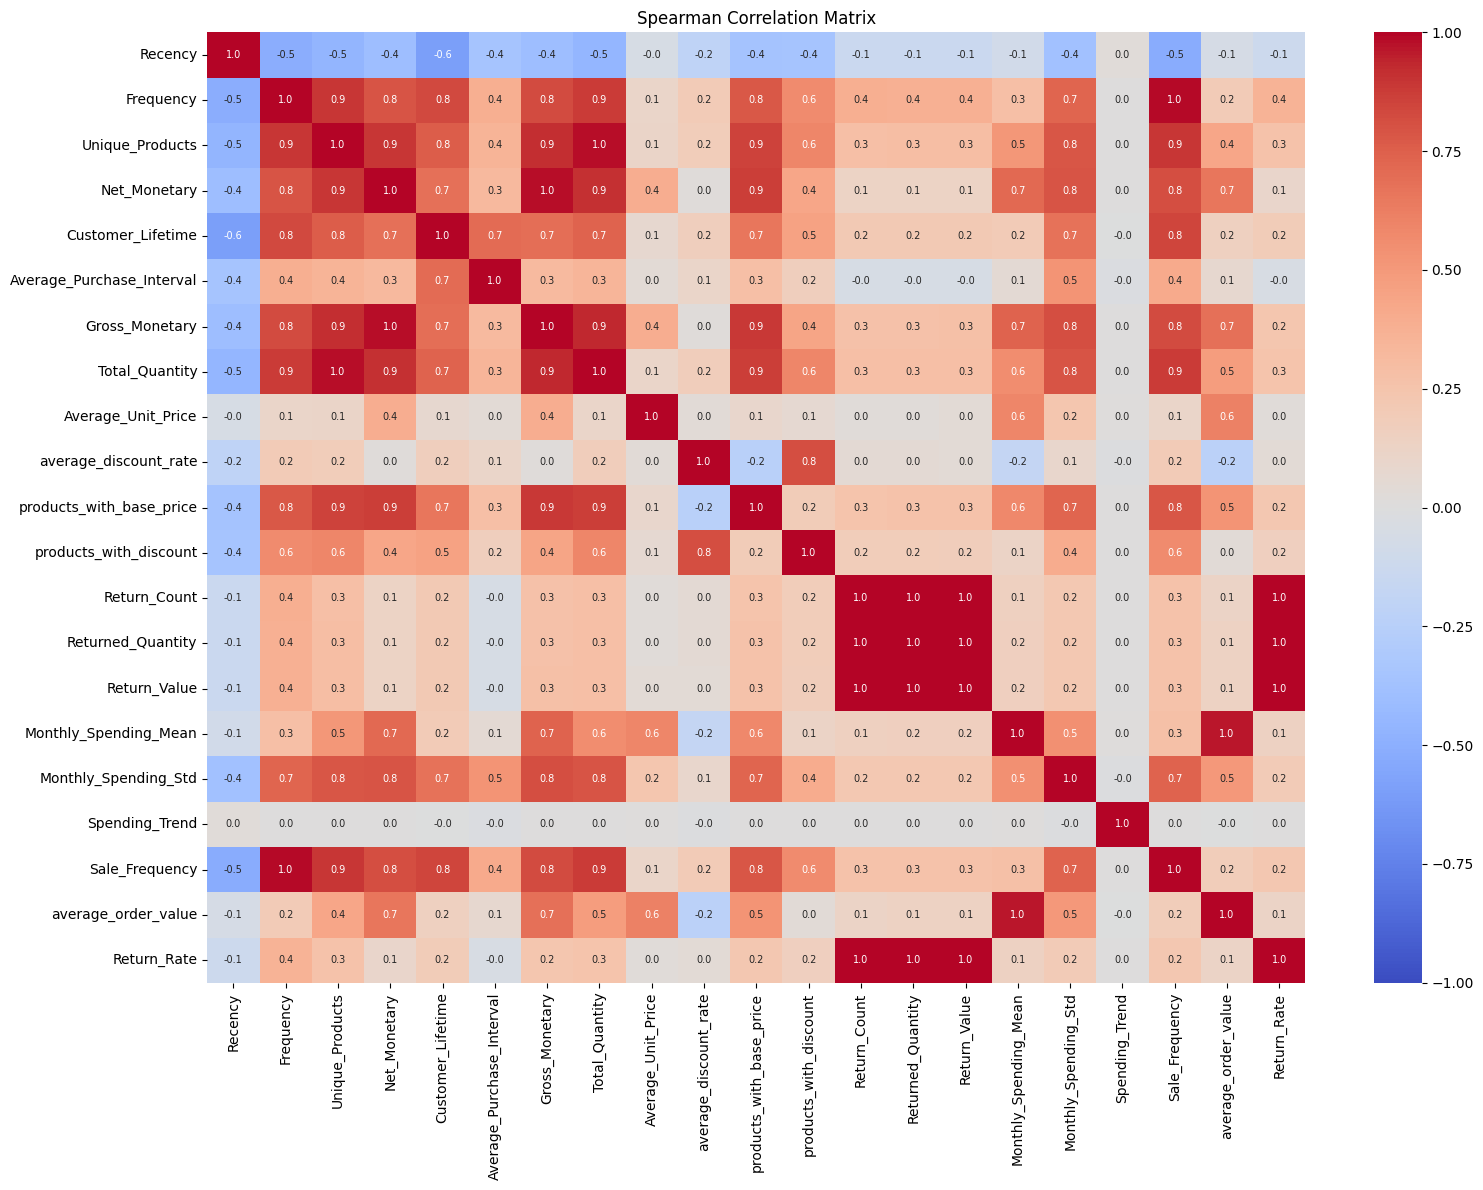

In [14]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    spearman_corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".1f",
    annot_kws={"size": 7}
)

plt.title("Spearman Correlation Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
# Extract unique feature pairs, avoiding duplicate pairs
upper = spearman_corr.where(
    np.triu(np.ones(spearman_corr.shape), k=1).astype(bool)
)

correlation_pairs = (
    upper.stack()
    .rename("Spearman_Correlation")
    .reset_index()
)

correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Spearman_Correlation"
]

correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Spearman_Correlation"].abs()
)

# Strong correlations for investigation
high_corr_pairs = (
    correlation_pairs[
        correlation_pairs["Absolute_Correlation"] >= 0.85
    ]
    .sort_values("Absolute_Correlation", ascending=False)
)

print("Number of highly correlated pairs:", len(high_corr_pairs))
display(high_corr_pairs.round(3))

Number of highly correlated pairs: 22


,Feature_1,Feature_2,Spearman_Correlation,Absolute_Correlation
182,Returned_Quantity,Return_Value,0.998,0.998
174,Return_Count,Returned_Quantity,0.997,0.997
175,Return_Count,Return_Value,0.996,0.996
181,Return_Count,Return_Rate,0.995,0.995
188,Returned_Quantity,Return_Rate,0.993,0.993
194,Return_Value,Return_Rate,0.992,0.992
36,Frequency,Sale_Frequency,0.988,0.988
43,Unique_Products,Total_Quantity,0.980,0.980
59,Net_Monetary,Gross_Monetary,0.979,0.979
198,Monthly_Spending_Mean,average_order_value,0.964,0.964


In [16]:
import numpy as np
import pandas as pd

X = X_candidates.copy()

variance_report = pd.DataFrame(index=X.columns)

variance_report["Unique_Values"] = X.nunique()
variance_report["Variance"] = X.var()
variance_report["Std_Dev"] = X.std()
variance_report["Min"] = X.min()
variance_report["Q25"] = X.quantile(0.25)
variance_report["Median"] = X.median()
variance_report["Q75"] = X.quantile(0.75)
variance_report["IQR"] = (
    variance_report["Q75"] - variance_report["Q25"]
)

# Percentage of customers with the most common value
variance_report["Dominant_Value_Pct"] = (
    X.apply(
        lambda col: col.value_counts(normalize=True).iloc[0] * 100
    )
)

# Percentage of customers with a value of zero
variance_report["Zero_Pct"] = (
    X.eq(0).mean() * 100
)

# Features with no variation
variance_report["Constant"] = (
    variance_report["Unique_Values"] <= 1
)

display(
    variance_report.sort_values(
        "Dominant_Value_Pct",
        ascending=False
    ).round(3)
)

,Unique_Values,Variance,Std_Dev,Min,Q25,Median,Q75,IQR,Dominant_Value_Pct,Zero_Pct,Constant
Return_Count,7,0.166,0.407,0.000,0.000,0.000,0.000,0.000,85.688,85.688,False
Returned_Quantity,19,0.776,0.881,0.000,0.000,0.000,0.000,0.000,85.688,85.688,False
Return_Value,28193,1852.747,43.044,0.000,0.000,0.000,0.000,0.000,85.688,85.688,False
Return_Rate,80,0.022,0.147,0.000,0.000,0.000,0.000,0.000,85.688,85.688,False
products_with_discount,30,4.131,2.033,0.000,0.000,1.000,2.000,2.000,38.428,38.428,False
average_discount_rate,2963,0.021,0.143,0.000,0.000,0.088,0.200,0.200,38.428,38.428,False
Monthly_Spending_Std,696651,2380.233,48.788,0.000,0.000,24.949,56.037,56.037,27.374,27.374,False
Spending_Trend,592578,2954.713,54.357,-992.180,-9.031,0.000,8.170,17.201,27.334,27.334,False
Average_Purchase_Interval,6707,17418.912,131.981,0.000,0.000,97.250,177.000,177.000,26.225,26.225,False
Customer_Lifetime,808,66784.525,258.427,0.000,0.000,323.000,547.000,547.000,26.225,26.225,False


In [17]:
# Screening flags, not automatic deletion rules
low_information_flags = variance_report[
    (variance_report["IQR"] == 0) |
    (variance_report["Dominant_Value_Pct"] >= 95)
].copy()

print("Features requiring further investigation:")
display(low_information_flags.round(3))

Features requiring further investigation:


,Unique_Values,Variance,Std_Dev,Min,Q25,Median,Q75,IQR,Dominant_Value_Pct,Zero_Pct,Constant
Return_Count,7,0.166,0.407,0.0,0.0,0.0,0.0,0.0,85.688,85.688,False
Returned_Quantity,19,0.776,0.881,0.0,0.0,0.0,0.0,0.0,85.688,85.688,False
Return_Value,28193,1852.747,43.044,0.0,0.0,0.0,0.0,0.0,85.688,85.688,False
Return_Rate,80,0.022,0.147,0.0,0.0,0.0,0.0,0.0,85.688,85.688,False


In [18]:
X = X_candidates.copy()

distribution_report = pd.DataFrame(index=X.columns)

distribution_report["Skewness"] = X.skew()
distribution_report["Q1"] = X.quantile(0.25)
distribution_report["Median"] = X.median()
distribution_report["Q3"] = X.quantile(0.75)
distribution_report["IQR"] = (
    distribution_report["Q3"] - distribution_report["Q1"]
)
distribution_report["Zero_Pct"] = X.eq(0).mean() * 100

# IQR-based outlier counts
lower_bounds = distribution_report["Q1"] - (
    1.5 * distribution_report["IQR"]
)
upper_bounds = distribution_report["Q3"] + (
    1.5 * distribution_report["IQR"]
)

distribution_report["Outlier_Count"] = (
    X.lt(lower_bounds, axis=1) |
    X.gt(upper_bounds, axis=1)
).sum()

distribution_report["Outlier_Pct"] = (
    distribution_report["Outlier_Count"] / len(X) * 100
)

display(
    distribution_report.sort_values(
        "Skewness", ascending=False
    ).round(3)
)

,Skewness,Q1,Median,Q3,IQR,Zero_Pct,Outlier_Count,Outlier_Pct
Return_Value,5.859,0.000,0.000,0.000,0.000,85.688,183670,14.312
Returned_Quantity,5.054,0.000,0.000,0.000,0.000,85.688,183670,14.312
Return_Rate,4.346,0.000,0.000,0.000,0.000,85.688,183670,14.312
average_order_value,3.028,39.760,57.499,83.160,43.400,0.000,67370,5.250
Monthly_Spending_Mean,2.720,41.580,62.100,91.886,50.306,0.000,61295,4.776
Return_Count,2.717,0.000,0.000,0.000,0.000,85.688,183670,14.312
products_with_discount,2.275,0.000,1.000,2.000,2.000,38.428,68604,5.346
Monthly_Spending_Std,2.225,0.000,24.949,56.037,56.037,27.374,60209,4.692
Gross_Monetary,2.072,75.180,162.972,317.500,242.320,0.000,63492,4.947
Net_Monetary,2.072,70.490,154.216,301.406,230.916,0.882,63624,4.958


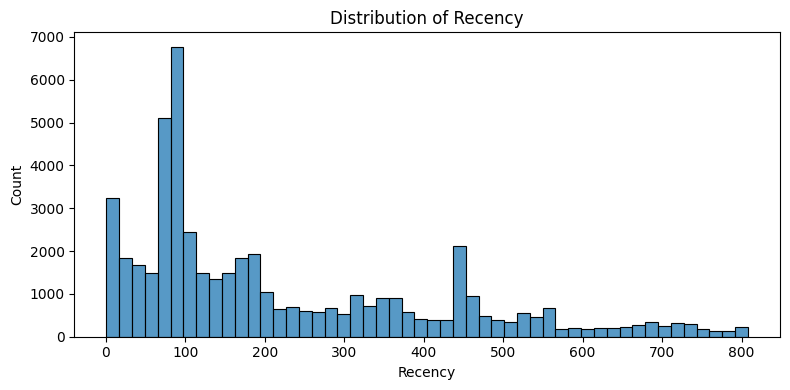

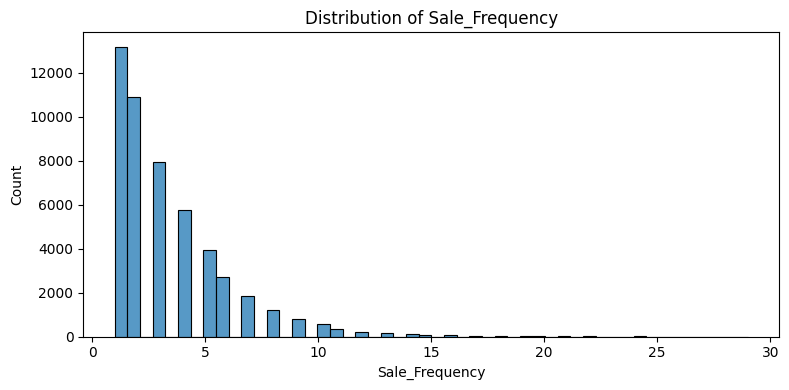

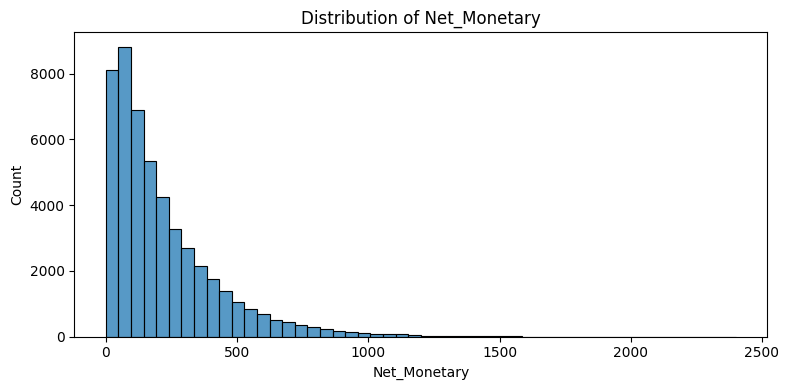

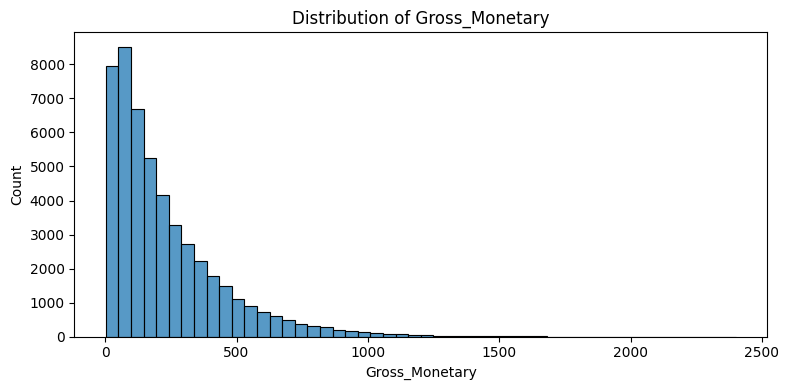

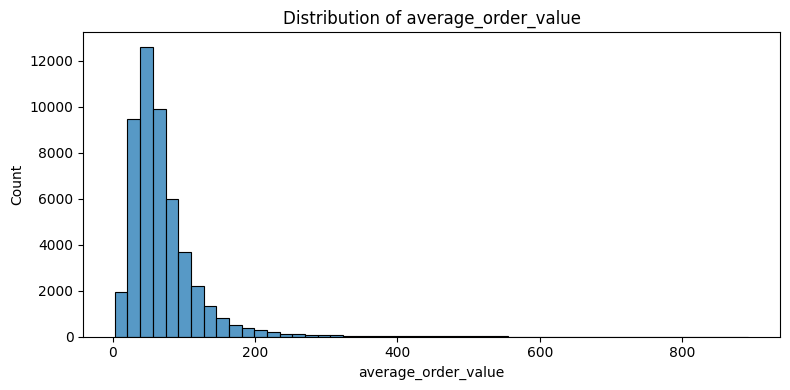

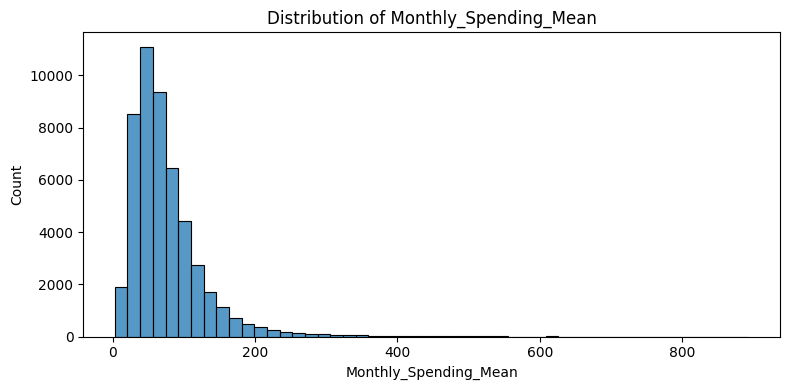

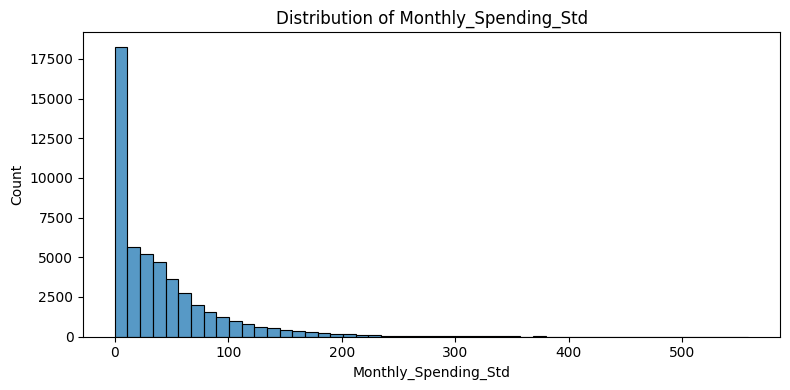

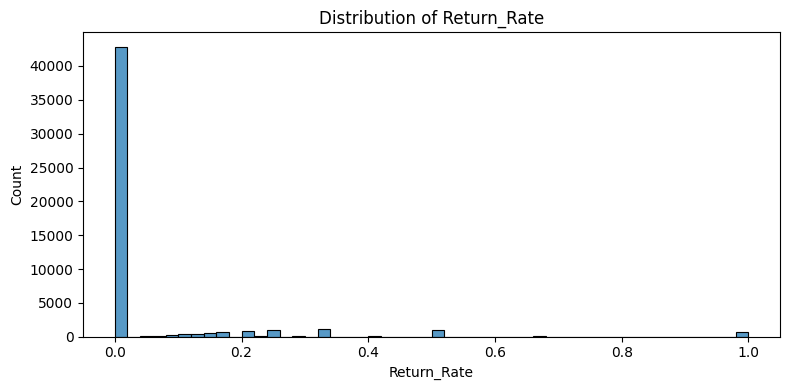

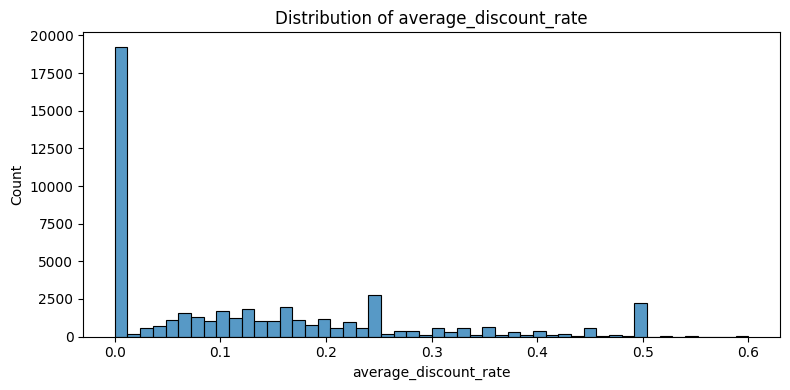

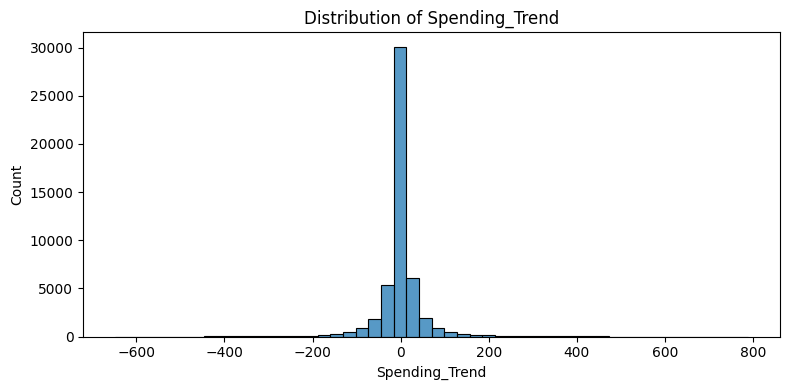

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

features_to_plot = [
    "Recency",
    "Sale_Frequency",
    "Net_Monetary",
    "Gross_Monetary",
    "average_order_value",
    "Monthly_Spending_Mean",
    "Monthly_Spending_Std",
    "Return_Rate",
    "average_discount_rate",
    "Spending_Trend"
]

for feature in features_to_plot:
    if feature not in X.columns:
        continue

    plt.figure(figsize=(8, 4))
    sns.histplot(
        X[feature].sample(
            n=min(50000, len(X)),
            random_state=42
        ),
        bins=50
    )
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.tight_layout()
    plt.show()

In [20]:
for feature in [
    "Net_Monetary",
    "Gross_Monetary",
    "Return_Value",
    "Spending_Trend"
]:
    if feature not in X.columns:
        continue

    print(f"\n{feature}")
    print("Negative values:", int((X[feature] < 0).sum()))
    print("Zero values:", int((X[feature] == 0).sum()))
    print("Positive values:", int((X[feature] > 0).sum()))


Net_Monetary
Negative values: 0
Zero values: 11321
Positive values: 1272025

Gross_Monetary
Negative values: 0
Zero values: 0
Positive values: 1283346

Return_Value
Negative values: 0
Zero values: 1099676
Positive values: 183670

Spending_Trend
Negative values: 473013
Zero values: 350795
Positive values: 459538


In [21]:
candidate_features = [
    "Recency",
    "Sale_Frequency",
    "Customer_Lifetime",
    "Net_Monetary",
    "Unique_Products",
    "Average_Unit_Price",
    "average_discount_rate",
    "products_with_discount",
    "Monthly_Spending_Mean",
    "Monthly_Spending_Std",
    "Spending_Trend",
    "Return_Rate"
]

X_initial = customer_df[candidate_features].copy()

print("Initial feature matrix:", X_initial.shape)
display(X_initial.describe().T)

Initial feature matrix: (1283346, 12)


,count,mean,std,min,25%,50%,75%,max
Recency,1283346.0,218.747141,194.285354,1.000,81.000000,141.000000,346.000000,808.000000
Sale_Frequency,1283346.0,3.379312,2.633096,1.000,1.000000,3.000000,4.000000,35.000000
Customer_Lifetime,1283346.0,313.118456,258.427020,0.000,0.000000,323.000000,547.000000,807.000000
Net_Monetary,1283346.0,220.953799,213.372211,0.000,70.490000,154.216100,301.406400,3054.108400
Unique_Products,1283346.0,4.731779,4.135002,1.000,2.000000,3.000000,6.000000,59.000000
Average_Unit_Price,1283346.0,50.999781,17.721941,3.175,39.681818,49.200000,59.690000,161.490000
average_discount_rate,1283346.0,0.125987,0.143333,0.000,0.000000,0.087500,0.200000,0.600000
products_with_discount,1283346.0,1.533257,2.032525,0.000,0.000000,1.000000,2.000000,32.000000
Monthly_Spending_Mean,1283346.0,74.185179,50.951741,1.778,41.580000,62.100000,91.886400,1040.904000
Monthly_Spending_Std,1283346.0,39.278491,48.787636,0.000,0.000000,24.949273,56.036639,743.699557


In [22]:
from sklearn.preprocessing import (
    FunctionTransformer,
    PowerTransformer,
    StandardScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np

log_features = [
    "Recency",
    "Sale_Frequency",
    "Customer_Lifetime",
    "Net_Monetary",
    "Unique_Products",
    "Average_Unit_Price",
    "Monthly_Spending_Mean",
    "Monthly_Spending_Std",
    "products_with_discount"
]

rate_features = [
    "average_discount_rate",
    "Return_Rate"
]

trend_features = ["Spending_Trend"]

# Log transformation followed by standardization
log_pipeline = Pipeline([
    ("log", FunctionTransformer(np.log1p, validate=False)),
    ("scale", StandardScaler())
])

# Yeo-Johnson supports both negative and positive values
trend_pipeline = Pipeline([
    ("power", PowerTransformer(method="yeo-johnson")),
    ("scale", StandardScaler())
])

# Standardize the two rate features
rate_pipeline = Pipeline([
    ("scale", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("log_features", log_pipeline, log_features),
    ("trend", trend_pipeline, trend_features),
    ("rates", rate_pipeline, rate_features)
])

X_scaled = preprocessor.fit_transform(X_initial)

print("Scaled matrix shape:", X_scaled.shape)
print("Contains NaN:", np.isnan(X_scaled).any())
print("Contains infinity:", np.isinf(X_scaled).any())
print("Mean of first 5 features:", X_scaled[:, :5].mean(axis=0))
print("Std of first 5 features:", X_scaled[:, :5].std(axis=0))

Scaled matrix shape: (1283346, 12)
Contains NaN: False
Contains infinity: False
Mean of first 5 features: [3.93712827e-15 2.55128463e-17 7.03020654e-16 4.48600881e-16
 1.60589194e-15]
Std of first 5 features: [1. 1. 1. 1. 1.]


In [23]:
import numpy as np
import pandas as pd

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# Column order produced by your ColumnTransformer
scaled_feature_names = (
    log_features + trend_features + rate_features
)

assert X_scaled.shape[1] == len(scaled_feature_names)

# Define alternative feature sets
feature_sets = {
    "A_Baseline_12": scaled_feature_names,

    "B_Core_6": [
        "Recency",
        "Sale_Frequency",
        "Net_Monetary",
        "Unique_Products",
        "average_discount_rate",
        "Return_Rate"
    ],

    "C_Extended_10": [
        "Recency",
        "Sale_Frequency",
        "Net_Monetary",
        "Unique_Products",
        "average_discount_rate",
        "Return_Rate",
        "Customer_Lifetime",
        "Monthly_Spending_Mean",
        "Monthly_Spending_Std",
        "Spending_Trend"
    ]
}

# Reproducible sampling
rng = np.random.default_rng(42)

n = X_scaled.shape[0]
train_size = min(30000, n)
eval_size = min(3000, train_size)

train_idx = rng.choice(n, size=train_size, replace=False)

# Use the same training customers for every feature set
results = []
models = {}

for set_name, features in feature_sets.items():

    feature_idx = [
        scaled_feature_names.index(f)
        for f in features
    ]

    X_train = X_scaled[np.ix_(train_idx, feature_idx)]

    # Use the same evaluation subset for every K in this set
    eval_idx = rng.choice(
        len(X_train),
        size=eval_size,
        replace=False
    )

    X_eval = X_train[eval_idx]

    for k in range(2, 9):

        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=42,
            batch_size=2048,
            n_init=3,
            max_iter=100
        )

        labels_train = model.fit_predict(X_train)
        labels_eval = model.predict(X_eval)

        silhouette = silhouette_score(
            X_eval,
            labels_eval
        )

        db_index = davies_bouldin_score(
            X_eval,
            labels_eval
        )

        cluster_sizes = pd.Series(labels_train).value_counts(
            normalize=True
        )

        results.append({
            "Feature_Set": set_name,
            "N_Features": len(features),
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette": silhouette,
            "Davies_Bouldin": db_index,
            "Smallest_Cluster_Pct": (
                cluster_sizes.min() * 100
            ),
            "Largest_Cluster_Pct": (
                cluster_sizes.max() * 100
            )
        })

        models[(set_name, k)] = model

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ["Feature_Set", "K"]
    ).round(4)
)

,Feature_Set,N_Features,K,Inertia,Silhouette,Davies_Bouldin,Smallest_Cluster_Pct,Largest_Cluster_Pct
0,A_Baseline_12,12,2,255756.0620,0.2794,1.4292,42.4700,57.5300
1,A_Baseline_12,12,3,222005.7248,0.1970,1.7169,27.3800,38.8800
2,A_Baseline_12,12,4,211646.1290,0.1625,1.9149,18.6000,28.3767
3,A_Baseline_12,12,5,196445.9172,0.1552,1.9616,13.2867,27.4067
4,A_Baseline_12,12,6,175277.9933,0.1932,1.6167,1.3233,35.4467
5,A_Baseline_12,12,7,168343.7485,0.1885,1.5877,6.7200,21.0833
6,A_Baseline_12,12,8,150633.3419,0.1869,1.5289,2.9600,20.5100
7,B_Core_6,6,2,120910.3197,0.3071,1.2450,45.6333,54.3667
8,B_Core_6,6,3,101869.2850,0.3111,1.2804,18.1233,44.2700
9,B_Core_6,6,4,80574.6692,0.3282,1.0360,3.6100,45.9433


In [24]:
best_results = (
    results_df
    .sort_values(
        ["Feature_Set", "Silhouette"],
        ascending=[True, False]
    )
    .groupby("Feature_Set")
    .head(3)
)

display(best_results.round(4))

,Feature_Set,N_Features,K,Inertia,Silhouette,Davies_Bouldin,Smallest_Cluster_Pct,Largest_Cluster_Pct
0,A_Baseline_12,12,2,255756.0620,0.2794,1.4292,42.4700,57.5300
1,A_Baseline_12,12,3,222005.7248,0.1970,1.7169,27.3800,38.8800
4,A_Baseline_12,12,6,175277.9933,0.1932,1.6167,1.3233,35.4467
9,B_Core_6,6,4,80574.6692,0.3282,1.0360,3.6100,45.9433
8,B_Core_6,6,3,101869.2850,0.3111,1.2804,18.1233,44.2700
7,B_Core_6,6,2,120910.3197,0.3071,1.2450,45.6333,54.3667
14,C_Extended_10,10,2,200252.7952,0.3449,1.2255,34.2900,65.7100
17,C_Extended_10,10,5,142793.1147,0.2544,1.3981,7.6900,35.5733
18,C_Extended_10,10,6,135542.0190,0.2255,1.5434,3.2200,34.9300


In [25]:
import numpy as np
import pandas as pd

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

# Reuse the existing scaled matrix and feature ordering
rng = np.random.default_rng(42)

n = X_scaled.shape[0]

# Same customers for both candidates
train_idx = rng.choice(n, size=min(30000, n), replace=False)
eval_idx = rng.choice(train_idx, size=min(3000, len(train_idx)),
                      replace=False)

feature_sets_to_test = {
    "B_Core_6_K4": (
        feature_sets["B_Core_6"], 4
    ),
    "C_Extended_10_K2": (
        feature_sets["C_Extended_10"], 2
    )
}

seeds = [21, 42, 99]
stability_results = []
evaluation_labels = {}

for candidate, (features, k) in feature_sets_to_test.items():

    feature_idx = [
        scaled_feature_names.index(f) for f in features
    ]

    X_train = X_scaled[np.ix_(train_idx, feature_idx)]
    X_eval = X_scaled[np.ix_(eval_idx, feature_idx)]

    labels_by_seed = {}

    for seed in seeds:
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=seed,
            batch_size=2048,
            n_init=5,
            max_iter=100
        )

        model.fit(X_train)

        labels = model.predict(X_eval)
        labels_by_seed[seed] = labels

        stability_results.append({
            "Candidate": candidate,
            "Seed": seed,
            "Silhouette": silhouette_score(
                X_eval, labels
            ),
            "Davies_Bouldin": davies_bouldin_score(
                X_eval, labels
            ),
            "Smallest_Cluster_Pct": (
                pd.Series(labels).value_counts(normalize=True).min()
                * 100
            ),
            "Largest_Cluster_Pct": (
                pd.Series(labels).value_counts(normalize=True).max()
                * 100
            )
        })

    evaluation_labels[candidate] = labels_by_seed

stability_df = pd.DataFrame(stability_results)
display(stability_df.round(4))

,Candidate,Seed,Silhouette,Davies_Bouldin,Smallest_Cluster_Pct,Largest_Cluster_Pct
0,B_Core_6_K4,21,0.2090,1.4179,7.3333,37.6667
1,B_Core_6_K4,42,0.2384,1.3830,10.7667,37.9333
2,B_Core_6_K4,99,0.2628,1.2929,2.5667,37.9000
3,C_Extended_10_K2,21,0.3558,1.1962,31.4333,68.5667
4,C_Extended_10_K2,42,0.3491,1.2130,32.7667,67.2333
5,C_Extended_10_K2,99,0.3551,1.1977,31.5667,68.4333


In [26]:
ari_results = []

for candidate, labels_by_seed in evaluation_labels.items():
    for i, seed_a in enumerate(seeds):
        for seed_b in seeds[i + 1:]:
            ari = adjusted_rand_score(
                labels_by_seed[seed_a],
                labels_by_seed[seed_b]
            )

            ari_results.append({
                "Candidate": candidate,
                "Seed_A": seed_a,
                "Seed_B": seed_b,
                "ARI": ari
            })

ari_df = pd.DataFrame(ari_results)
display(ari_df.round(4))

,Candidate,Seed_A,Seed_B,ARI
0,B_Core_6_K4,21,42,0.5487
1,B_Core_6_K4,21,99,0.2734
2,B_Core_6_K4,42,99,0.4954
3,C_Extended_10_K2,21,42,0.9439
4,C_Extended_10_K2,21,99,0.9946
5,C_Extended_10_K2,42,99,0.9491


In [27]:
features = feature_sets["C_Extended_10"]

feature_idx = [
    scaled_feature_names.index(f) for f in features
]

X_train = X_scaled[np.ix_(train_idx, feature_idx)]
X_all = X_scaled[:, feature_idx]

final_candidate = MiniBatchKMeans(
    n_clusters=2,
    random_state=42,
    batch_size=2048,
    n_init=5,
    max_iter=100
)

final_candidate.fit(X_train)

cluster_labels = final_candidate.predict(X_all)

# Profile using the original, interpretable features
profile_df = customer_df[features].copy()
profile_df["Cluster"] = cluster_labels

cluster_profile = profile_df.groupby("Cluster").agg(
    Customer_Count=("Cluster", "size"),
    Recency_Median=("Recency", "median"),
    Sale_Frequency_Median=("Sale_Frequency", "median"),
    Net_Monetary_Median=("Net_Monetary", "median"),
    Unique_Products_Median=("Unique_Products", "median"),
    Monthly_Spending_Median=("Monthly_Spending_Mean", "median"),
    Return_Rate_Mean=("Return_Rate", "mean"),
    Spending_Trend_Median=("Spending_Trend", "median")
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(customer_df) * 100
)

display(cluster_profile.round(2))

,Customer_Count,Recency_Median,Sale_Frequency_Median,Net_Monetary_Median,Unique_Products_Median,Monthly_Spending_Median,Return_Rate_Mean,Spending_Trend_Median,Customer_Percentage
Cluster,,,,,,,,,
0,839776,93.0,4.0,239.00,5.0,70.33,0.05,-0.27,65.44
1,443570,354.0,1.0,51.44,1.0,42.12,0.05,0.00,34.56


In [28]:

import numpy as np
import pandas as pd

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

# Use the same feature set that performed best previously
features = feature_sets["C_Extended_10"]
feature_idx = [scaled_feature_names.index(f) for f in features]

# Use consistent training and evaluation samples
rng = np.random.default_rng(42)
n = X_scaled.shape[0]

train_idx = rng.choice(n, size=min(30000, n), replace=False)
eval_idx = rng.choice(
    train_idx,
    size=min(3000, len(train_idx)),
    replace=False
)

X_train = X_scaled[np.ix_(train_idx, feature_idx)]
X_eval = X_scaled[np.ix_(eval_idx, feature_idx)]

results = []
labels_by_k = {}

# Test 3, 4, 5, and 6 clusters
for k in [3, 4, 5, 6]:
    labels_by_k[k] = {}

    for seed in [21, 42, 99]:
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=seed,
            batch_size=2048,
            n_init=5,
            max_iter=150
        )

        model.fit(X_train)
        labels = model.predict(X_eval)

        counts = np.bincount(labels, minlength=k)
        percentages = counts / len(labels) * 100

        results.append({
            "K": k,
            "Seed": seed,
            "Silhouette": silhouette_score(
                X_eval, labels, sample_size=None
            ),
            "Davies_Bouldin": davies_bouldin_score(
                X_eval, labels
            ),
            "Smallest_Cluster_Pct": percentages.min(),
            "Largest_Cluster_Pct": percentages.max()
        })

        labels_by_k[k][seed] = labels

results_df = pd.DataFrame(results)

print("METRICS BY K AND RANDOM SEED")
display(results_df.round(4))

# Average metrics across seeds
summary = results_df.groupby("K").agg(
    Mean_Silhouette=("Silhouette", "mean"),
    Std_Silhouette=("Silhouette", "std"),
    Mean_Davies_Bouldin=("Davies_Bouldin", "mean"),
    Mean_Smallest_Cluster_Pct=("Smallest_Cluster_Pct", "mean"),
    Mean_Largest_Cluster_Pct=("Largest_Cluster_Pct", "mean")
).reset_index()

print("SUMMARY BY NUMBER OF CLUSTERS")
display(summary.round(4))

# Compare assignments across random seeds
stability = []

for k in [3, 4, 5, 6]:
    for seed_a, seed_b in [(21, 42), (21, 99), (42, 99)]:
        ari = adjusted_rand_score(
            labels_by_k[k][seed_a],
            labels_by_k[k][seed_b]
        )

        stability.append({
            "K": k,
            "Seed_Pair": f"{seed_a}-{seed_b}",
            "ARI": ari
        })

print("STABILITY COMPARISON")
display(pd.DataFrame(stability).round(4))


METRICS BY K AND RANDOM SEED


,K,Seed,Silhouette,Davies_Bouldin,Smallest_Cluster_Pct,Largest_Cluster_Pct
0,3,21,0.2203,1.5863,26.1333,42.4333
1,3,42,0.2294,1.5673,26.4667,39.7000
2,3,99,0.2259,1.5930,26.3333,39.3000
3,4,21,0.2353,1.5587,9.8667,38.5000
4,4,42,0.1708,1.9286,22.1333,27.8000
5,4,99,0.3292,1.2278,4.8333,63.5333
6,5,21,0.2206,1.6316,7.1333,28.7000
7,5,42,0.2524,1.3610,7.3667,36.8667
8,5,99,0.2485,1.3376,3.3333,38.4667
9,6,21,0.2266,1.4567,1.2000,25.2667


SUMMARY BY NUMBER OF CLUSTERS


,K,Mean_Silhouette,Std_Silhouette,Mean_Davies_Bouldin,Mean_Smallest_Cluster_Pct,Mean_Largest_Cluster_Pct
0,3,0.2252,0.0046,1.5822,26.3111,40.4778
1,4,0.2451,0.0796,1.5717,12.2778,43.2778
2,5,0.2405,0.0174,1.4434,5.9444,34.6778
3,6,0.2223,0.0079,1.4999,2.0333,28.9556


STABILITY COMPARISON


,K,Seed_Pair,ARI
0,3,21-42,0.7442
1,3,21-99,0.8695
2,3,42-99,0.7929
3,4,21-42,0.5058
4,4,21-99,0.4205
5,4,42-99,0.2773
6,5,21-42,0.6961
7,5,21-99,0.5696
8,5,42-99,0.7038
9,6,21-42,0.4312


In [29]:

import numpy as np
import pandas as pd

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

# Use the same extended feature set for every K
features = feature_sets["C_Extended_10"]
feature_idx = [
    scaled_feature_names.index(f)
    for f in features
]

# Create fixed training and evaluation samples
rng = np.random.default_rng(42)
n = X_scaled.shape[0]

train_idx = rng.choice(
    n, size=min(30000, n), replace=False
)

eval_idx = rng.choice(
    train_idx,
    size=min(3000, len(train_idx)),
    replace=False
)

X_train = X_scaled[np.ix_(train_idx, feature_idx)]
X_eval = X_scaled[np.ix_(eval_idx, feature_idx)]

# Use the same seeds for every K
seeds = [21, 42, 99]
k_values = [2, 3, 4, 5]

results = []
labels_by_k = {}

for k in k_values:
    labels_by_k[k] = {}

    for seed in seeds:
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=seed,
            batch_size=2048,
            n_init=5,
            max_iter=150
        )

        model.fit(X_train)
        labels = model.predict(X_eval)

        counts = np.bincount(labels, minlength=k)
        percentages = counts / len(labels) * 100

        results.append({
            "K": k,
            "Seed": seed,
            "Silhouette": silhouette_score(
                X_eval, labels
            ),
            "Davies_Bouldin": davies_bouldin_score(
                X_eval, labels
            ),
            "Smallest_Cluster_Pct": percentages.min(),
            "Largest_Cluster_Pct": percentages.max()
        })

        labels_by_k[k][seed] = labels

results_df = pd.DataFrame(results)

print("RESULTS FOR EACH K AND SEED")
display(results_df.round(4))

# Summarize average performance and variation
summary = results_df.groupby("K").agg(
    Mean_Silhouette=("Silhouette", "mean"),
    Std_Silhouette=("Silhouette", "std"),
    Mean_Davies_Bouldin=("Davies_Bouldin", "mean"),
    Mean_Smallest_Cluster_Pct=(
        "Smallest_Cluster_Pct", "mean"
    ),
    Mean_Largest_Cluster_Pct=(
        "Largest_Cluster_Pct", "mean"
    )
).reset_index()

print("AVERAGE PERFORMANCE COMPARISON")
display(summary.round(4))

# Compare stability across random seeds
stability_results = []

for k in k_values:
    for seed_a, seed_b in [
        (21, 42), (21, 99), (42, 99)
    ]:
        ari = adjusted_rand_score(
            labels_by_k[k][seed_a],
            labels_by_k[k][seed_b]
        )

        stability_results.append({
            "K": k,
            "Seed_Pair": f"{seed_a}-{seed_b}",
            "ARI": ari
        })

stability_df = pd.DataFrame(stability_results)

print("STABILITY ACROSS RANDOM SEEDS")
display(stability_df.round(4))

print("AVERAGE STABILITY BY K")
display(
    stability_df.groupby("K")["ARI"]
    .mean()
    .reset_index(name="Mean_ARI")
    .round(4)
)


RESULTS FOR EACH K AND SEED


,K,Seed,Silhouette,Davies_Bouldin,Smallest_Cluster_Pct,Largest_Cluster_Pct
0,2,21,0.3558,1.1962,31.4333,68.5667
1,2,42,0.3491,1.2130,32.7667,67.2333
2,2,99,0.3551,1.1977,31.5667,68.4333
3,3,21,0.2203,1.5863,26.1333,42.4333
4,3,42,0.2294,1.5673,26.4667,39.7000
5,3,99,0.2259,1.5930,26.3333,39.3000
6,4,21,0.2353,1.5587,9.8667,38.5000
7,4,42,0.1708,1.9286,22.1333,27.8000
8,4,99,0.3292,1.2278,4.8333,63.5333
9,5,21,0.2206,1.6316,7.1333,28.7000


AVERAGE PERFORMANCE COMPARISON


,K,Mean_Silhouette,Std_Silhouette,Mean_Davies_Bouldin,Mean_Smallest_Cluster_Pct,Mean_Largest_Cluster_Pct
0,2,0.3533,0.0037,1.2023,31.9222,68.0778
1,3,0.2252,0.0046,1.5822,26.3111,40.4778
2,4,0.2451,0.0796,1.5717,12.2778,43.2778
3,5,0.2405,0.0174,1.4434,5.9444,34.6778


STABILITY ACROSS RANDOM SEEDS


,K,Seed_Pair,ARI
0,2,21-42,0.9439
1,2,21-99,0.9946
2,2,42-99,0.9491
3,3,21-42,0.7442
4,3,21-99,0.8695
5,3,42-99,0.7929
6,4,21-42,0.5058
7,4,21-99,0.4205
8,4,42-99,0.2773
9,5,21-42,0.6961


AVERAGE STABILITY BY K


,K,Mean_ARI
0,2,0.9625
1,3,0.8022
2,4,0.4012
3,5,0.6565


In [30]:

models = {}
all_cluster_labels = {}

X_all = X_scaled[:, feature_idx]

for k in [4, 5]:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=5,
        max_iter=150
    )

    model.fit(X_train)

    labels = model.predict(X_all)

    models[k] = model
    all_cluster_labels[k] = labels

    print(f"\nK = {k}: Full dataset cluster sizes")

    counts = pd.Series(labels).value_counts().sort_index()

    size_table = pd.DataFrame({
        "Customer_Count": counts,
        "Customer_Percentage": (
            counts / len(labels) * 100
        )
    })

    display(size_table.round(2))



K = 4: Full dataset cluster sizes


,Customer_Count,Customer_Percentage
0,349030,27.20
1,330992,25.79
2,294440,22.94
3,308884,24.07



K = 5: Full dataset cluster sizes


,Customer_Count,Customer_Percentage
0,259766,20.24
1,101709,7.93
2,456700,35.59
3,364898,28.43
4,100273,7.81


In [31]:

profile_columns = [
    "Recency",
    "Sale_Frequency",
    "Customer_Lifetime",
    "Net_Monetary",
    "Unique_Products",
    "Average_Unit_Price",
    "average_discount_rate",
    "Monthly_Spending_Mean",
    "Monthly_Spending_Std",
    "Spending_Trend",
    "Return_Rate"
]

# Use original, interpretable feature values
profile_data = customer_df[profile_columns].copy()

# Build one profile table for each K
profiles = {}

for k in [4, 5]:
    temp = profile_data.copy()
    temp["Cluster"] = all_cluster_labels[k]

    # Medians are robust for skewed spending variables
    medians = temp.groupby("Cluster")[profile_columns].median()

    # Mean return rate can be useful alongside the median
    return_means = temp.groupby("Cluster")["Return_Rate"].mean()

    counts = temp.groupby("Cluster").size()

    profile = medians.copy()
    profile.insert(0, "Customer_Count", counts)
    profile.insert(
        1,
        "Customer_Percentage",
        counts / len(customer_df) * 100
    )
    profile["Return_Rate_Mean"] = return_means

    profiles[k] = profile

    print(f"\nCUSTOMER PROFILES — K = {k}")
    display(profile.round(2))



CUSTOMER PROFILES — K = 4


,Customer_Count,Customer_Percentage,Recency,Sale_Frequency,Customer_Lifetime,Net_Monetary,Unique_Products,Average_Unit_Price,average_discount_rate,Monthly_Spending_Mean,Monthly_Spending_Std,Spending_Trend,Return_Rate,Return_Rate_Mean
Cluster,,,,,,,,,,,,,,
0,349030,27.20,370.0,1.0,0.0,45.90,1.0,45.46,0.00,47.79,0.00,0.00,0.0,0.05
1,330992,25.79,103.0,4.0,443.0,220.86,5.0,51.64,0.10,68.26,40.60,10.26,0.0,0.04
2,294440,22.94,81.0,6.0,592.0,454.09,9.0,52.52,0.10,92.84,73.28,-4.30,0.0,0.05
3,308884,24.07,185.0,2.0,294.0,99.50,3.0,44.00,0.13,42.75,17.18,-5.75,0.0,0.05



CUSTOMER PROFILES — K = 5


,Customer_Count,Customer_Percentage,Recency,Sale_Frequency,Customer_Lifetime,Net_Monetary,Unique_Products,Average_Unit_Price,average_discount_rate,Monthly_Spending_Mean,Monthly_Spending_Std,Spending_Trend,Return_Rate,Return_Rate_Mean
Cluster,,,,,,,,,,,,,,
0,259766,20.24,379.0,1.0,0.0,55.08,1.0,45.50,0.00,56.70,0.00,0.00,0.0,0.05
1,101709,7.93,177.0,3.0,321.0,251.44,5.0,56.35,0.05,103.41,77.82,78.80,0.0,0.06
2,456700,35.59,148.0,3.0,357.0,129.26,3.0,46.30,0.12,48.90,22.40,-3.89,0.0,0.04
3,364898,28.43,81.0,6.0,587.0,399.55,8.0,52.00,0.11,83.90,61.45,-2.30,0.0,0.05
4,100273,7.81,354.0,1.0,0.0,29.90,1.0,44.28,0.50,28.35,0.00,0.00,0.0,0.05


In [32]:

comparison_rows = []

for k in [4, 5]:
    profile = profiles[k]

    for cluster_id, row in profile.iterrows():
        comparison_rows.append({
            "K": k,
            "Cluster": cluster_id,
            "Customers": int(row["Customer_Count"]),
            "Customer_Pct": row["Customer_Percentage"],
            "Recency_Median": row["Recency"],
            "Frequency_Median": row["Sale_Frequency"],
            "Net_Monetary_Median": row["Net_Monetary"],
            "Products_Median": row["Unique_Products"],
            "Monthly_Spending_Median": row["Monthly_Spending_Mean"],
            "Discount_Rate_Median": row["average_discount_rate"],
            "Return_Rate_Mean": row["Return_Rate_Mean"],
            "Spending_Trend_Median": row["Spending_Trend"]
        })

comparison_df = pd.DataFrame(comparison_rows)

print("SIDE-BY-SIDE CLUSTER PROFILE COMPARISON")
display(
    comparison_df.sort_values(["K", "Cluster"])
    .round(2)
)


SIDE-BY-SIDE CLUSTER PROFILE COMPARISON


,K,Cluster,Customers,Customer_Pct,Recency_Median,Frequency_Median,Net_Monetary_Median,Products_Median,Monthly_Spending_Median,Discount_Rate_Median,Return_Rate_Mean,Spending_Trend_Median
0,4,0,349030,27.20,370.0,1.0,45.90,1.0,47.79,0.00,0.05,0.00
1,4,1,330992,25.79,103.0,4.0,220.86,5.0,68.26,0.10,0.04,10.26
2,4,2,294440,22.94,81.0,6.0,454.09,9.0,92.84,0.10,0.05,-4.30
3,4,3,308884,24.07,185.0,2.0,99.50,3.0,42.75,0.13,0.05,-5.75
4,5,0,259766,20.24,379.0,1.0,55.08,1.0,56.70,0.00,0.05,0.00
5,5,1,101709,7.93,177.0,3.0,251.44,5.0,103.41,0.05,0.06,78.80
6,5,2,456700,35.59,148.0,3.0,129.26,3.0,48.90,0.12,0.04,-3.89
7,5,3,364898,28.43,81.0,6.0,399.55,8.0,83.90,0.11,0.05,-2.30
8,5,4,100273,7.81,354.0,1.0,29.90,1.0,28.35,0.50,0.05,0.00


In [33]:

import numpy as np
import pandas as pd

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
K = 4
N_TRAIN = 100_000
N_EVAL = 5_000

N_REPEATS = 5
SEEDS = [21, 42, 99, 123, 2026]

# Use the same extended feature set
features = feature_sets["C_Extended_10"]

feature_idx = [
    scaled_feature_names.index(f)
    for f in features
]

X_all = X_scaled[:, feature_idx]
n = X_all.shape[0]

# --------------------------------------------------
# 2. Create one fixed evaluation sample
# --------------------------------------------------
rng_eval = np.random.default_rng(777)

eval_idx = rng_eval.choice(
    n,
    size=min(N_EVAL, n),
    replace=False
)

X_eval = X_all[eval_idx]

# Keep evaluation labels from every model
eval_labels = {}

# Keep models and their training indices
models = {}
training_indices = {}

results = []

# --------------------------------------------------
# 3. Independently sample training sets
# --------------------------------------------------
for run, seed in enumerate(SEEDS[:N_REPEATS], start=1):

    rng = np.random.default_rng(seed)

    train_idx = rng.choice(
        n,
        size=min(N_TRAIN, n),
        replace=False
    )

    X_train = X_all[train_idx]

    model = MiniBatchKMeans(
        n_clusters=K,
        random_state=seed,
        batch_size=4096,
        n_init=10,
        max_iter=200,
        reassignment_ratio=0.01
    )

    model.fit(X_train)

    # Predict the same evaluation customers
    labels = model.predict(X_eval)

    counts = np.bincount(labels, minlength=K)
    percentages = counts / len(labels) * 100

    eval_labels[run] = labels
    models[run] = model
    training_indices[run] = train_idx

    results.append({
        "Run": run,
        "Seed": seed,
        "Silhouette": silhouette_score(
            X_eval, labels
        ),
        "Davies_Bouldin": davies_bouldin_score(
            X_eval, labels
        ),
        "Smallest_Cluster_Pct": percentages.min(),
        "Largest_Cluster_Pct": percentages.max(),
        "Empty_Clusters": int(np.sum(counts == 0))
    })

    print(
        f"Completed run {run}/{N_REPEATS} "
        f"(seed={seed})"
    )

# --------------------------------------------------
# 4. Display metrics
# --------------------------------------------------
stability_results = pd.DataFrame(results)

print("\nK=4 STABILITY RESULTS")
display(stability_results.round(4))

print("\nSUMMARY ACROSS RUNS")

summary = stability_results[
    [
        "Silhouette",
        "Davies_Bouldin",
        "Smallest_Cluster_Pct",
        "Largest_Cluster_Pct"
    ]
].agg(["mean", "std", "min", "max"]).T

display(summary.round(4))


Completed run 1/5 (seed=21)
Completed run 2/5 (seed=42)
Completed run 3/5 (seed=99)
Completed run 4/5 (seed=123)
Completed run 5/5 (seed=2026)

K=4 STABILITY RESULTS


,Run,Seed,Silhouette,Davies_Bouldin,Smallest_Cluster_Pct,Largest_Cluster_Pct,Empty_Clusters
0,1,21,0.2533,1.4003,7.56,37.54,0
1,2,42,0.2548,1.4043,7.44,37.04,0
2,3,99,0.2161,1.6621,13.50,29.98,0
3,4,123,0.2548,1.4086,7.86,40.42,0
4,5,2026,0.2255,1.7229,7.00,50.64,0



SUMMARY ACROSS RUNS


,mean,std,min,max
Silhouette,0.2409,0.0187,0.2161,0.2548
Davies_Bouldin,1.5197,0.1593,1.4003,1.7229
Smallest_Cluster_Pct,8.6720,2.7166,7.0000,13.5000
Largest_Cluster_Pct,39.1240,7.4960,29.9800,50.6400


In [34]:

from itertools import combinations

ari_results = []

for run_a, run_b in combinations(
    sorted(eval_labels.keys()), 2
):
    ari = adjusted_rand_score(
        eval_labels[run_a],
        eval_labels[run_b]
    )

    ari_results.append({
        "Run_A": run_a,
        "Run_B": run_b,
        "ARI": ari
    })

ari_df = pd.DataFrame(ari_results)

print("PAIRWISE ARI ON THE SAME EVALUATION CUSTOMERS")
display(ari_df.round(4))

print("\nARI SUMMARY")

ari_summary = pd.DataFrame({
    "Mean_ARI": [ari_df["ARI"].mean()],
    "Std_ARI": [ari_df["ARI"].std()],
    "Min_ARI": [ari_df["ARI"].min()],
    "Max_ARI": [ari_df["ARI"].max()]
})

display(ari_summary.round(4))


PAIRWISE ARI ON THE SAME EVALUATION CUSTOMERS


,Run_A,Run_B,ARI
0,1,2,0.9067
1,1,3,0.6826
2,1,4,0.8209
3,1,5,0.3036
4,2,3,0.6666
5,2,4,0.7800
6,2,5,0.3088
7,3,4,0.6555
8,3,5,0.4073
9,4,5,0.3052



ARI SUMMARY


,Mean_ARI,Std_ARI,Min_ARI,Max_ARI
0,0.5837,0.2318,0.3036,0.9067


In [35]:

profile_columns = [
    "Recency",
    "Sale_Frequency",
    "Net_Monetary",
    "Unique_Products",
    "Monthly_Spending_Mean",
    "average_discount_rate",
    "Return_Rate",
    "Spending_Trend"
]

profiles_by_run = {}

for run, model in models.items():

    # Predict all customers using this run's model
    labels_all = model.predict(X_all)

    temp = customer_df[profile_columns].copy()
    temp["Cluster"] = labels_all

    profile = temp.groupby("Cluster").agg(
        Customer_Count=("Cluster", "size"),
        Recency_Median=("Recency", "median"),
        Frequency_Median=("Sale_Frequency", "median"),
        Net_Monetary_Median=("Net_Monetary", "median"),
        Unique_Products_Median=("Unique_Products", "median"),
        Monthly_Spending_Median=("Monthly_Spending_Mean", "median"),
        Discount_Rate_Median=("average_discount_rate", "median"),
        Return_Rate_Mean=("Return_Rate", "mean"),
        Spending_Trend_Median=("Spending_Trend", "median")
    )

    profile["Customer_Percentage"] = (
        profile["Customer_Count"] / len(customer_df) * 100
    )

    profiles_by_run[run] = profile

    print(f"\nCUSTOMER PROFILE — RUN {run}")
    display(profile.round(2))



CUSTOMER PROFILE — RUN 1


,Customer_Count,Recency_Median,Frequency_Median,Net_Monetary_Median,Unique_Products_Median,Monthly_Spending_Median,Discount_Rate_Median,Return_Rate_Mean,Spending_Trend_Median,Customer_Percentage
Cluster,,,,,,,,,,
0,473348,84.0,5.0,363.38,8.0,85.66,0.10,0.05,-0.04,36.88
1,258390,378.0,1.0,55.08,1.0,57.00,0.00,0.05,0.00,20.13
2,101133,354.0,1.0,29.97,1.0,28.50,0.50,0.05,0.00,7.88
3,450475,165.0,2.0,125.82,3.0,49.73,0.12,0.04,-0.65,35.10



CUSTOMER PROFILE — RUN 2


,Customer_Count,Recency_Median,Frequency_Median,Net_Monetary_Median,Unique_Products_Median,Monthly_Spending_Median,Discount_Rate_Median,Return_Rate_Mean,Spending_Trend_Median,Customer_Percentage
Cluster,,,,,,,,,,
0,99944,354.0,1.0,29.70,1.0,28.35,0.50,0.05,0.00,7.79
1,461092,84.0,5.0,365.89,8.0,85.07,0.10,0.05,1.70,35.93
2,463006,164.0,3.0,127.95,3.0,50.42,0.12,0.04,-3.12,36.08
3,259304,378.0,1.0,55.08,1.0,56.98,0.00,0.05,0.00,20.21



CUSTOMER PROFILE — RUN 3


,Customer_Count,Recency_Median,Frequency_Median,Net_Monetary_Median,Unique_Products_Median,Monthly_Spending_Median,Discount_Rate_Median,Return_Rate_Mean,Spending_Trend_Median,Customer_Percentage
Cluster,,,,,,,,,,
0,387887,154.0,3.0,114.50,3.0,44.82,0.12,0.04,-5.64,30.22
1,375152,81.0,6.0,393.12,8.0,82.96,0.10,0.05,-3.56,29.23
2,349074,371.0,1.0,45.78,1.0,47.62,0.00,0.05,0.00,27.20
3,171233,161.0,3.0,231.90,4.0,86.08,0.06,0.05,47.63,13.34



CUSTOMER PROFILE — RUN 4


,Customer_Count,Recency_Median,Frequency_Median,Net_Monetary_Median,Unique_Products_Median,Monthly_Spending_Median,Discount_Rate_Median,Return_Rate_Mean,Spending_Trend_Median,Customer_Percentage
Cluster,,,,,,,,,,
0,259900,379.0,1.0,55.08,1.0,56.70,0.00,0.05,0.00,20.25
1,402054,82.0,6.0,397.60,8.0,88.12,0.10,0.05,-0.81,31.33
2,516746,157.0,3.0,138.89,3.0,52.56,0.12,0.04,0.06,40.27
3,104646,353.0,1.0,30.51,1.0,28.28,0.50,0.05,0.00,8.15



CUSTOMER PROFILE — RUN 5


,Customer_Count,Recency_Median,Frequency_Median,Net_Monetary_Median,Unique_Products_Median,Monthly_Spending_Median,Discount_Rate_Median,Return_Rate_Mean,Spending_Trend_Median,Customer_Percentage
Cluster,,,,,,,,,,
0,155138,161.0,3.0,332.59,6.0,113.79,0.05,0.06,51.80,12.09
1,639597,87.0,4.0,206.50,5.0,58.16,0.12,0.04,-1.42,49.84
2,396695,368.0,1.0,48.06,1.0,43.50,0.00,0.05,0.00,30.91
3,91916,178.0,2.0,235.08,4.0,106.75,0.05,0.06,-87.53,7.16


In [36]:
from itertools import combinations
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

def stability_test(X, k, seeds=(21, 42, 99, 123, 2026), n_train=100_000, n_eval=5_000):
    eval_idx = np.random.default_rng(777).choice(len(X), size=min(n_eval, len(X)), replace=False)
    X_eval = X[eval_idx]
    labels, sils = [], []
    for s in seeds:
        tr = np.random.default_rng(s).choice(len(X), size=min(n_train, len(X)), replace=False)
        m = MiniBatchKMeans(n_clusters=k, random_state=s, batch_size=4096,
                            n_init=10, max_iter=200).fit(X[tr])
        lab = m.predict(X_eval)
        labels.append(lab)
        sils.append(silhouette_score(X_eval, lab))
    aris = [adjusted_rand_score(a, b) for a, b in combinations(labels, 2)]
    return {"K": k, "Mean_Silhouette": np.mean(sils),
            "Mean_ARI": np.mean(aris), "Min_ARI": np.min(aris)}

def idx_of(feats):
    return [scaled_feature_names.index(f) for f in feats]

# Test 1: lean feature set, all customers
lean = ['Recency', 'Sale_Frequency', 'Monthly_Spending_Mean',
        'average_discount_rate', 'Average_Unit_Price']
X_lean = X_scaled[:, idx_of(lean)]
print(pd.DataFrame([stability_test(X_lean, k) for k in [3, 4, 5]]).round(3))

# Test 2: repeat customers only, trend now meaningful
repeat_mask = (customer_df['Sale_Frequency'] > 1).values
rep_feats = ['Recency', 'Sale_Frequency', 'Monthly_Spending_Mean',
             'average_discount_rate', 'Spending_Trend']
X_rep = X_scaled[repeat_mask][:, idx_of(rep_feats)]
print(pd.DataFrame([stability_test(X_rep, k) for k in [3, 4, 5]]).round(3))

   K  Mean_Silhouette  Mean_ARI  Min_ARI
0  3            0.227     0.525    0.310
1  4            0.249     0.904    0.825
2  5            0.225     0.609    0.471
   K  Mean_Silhouette  Mean_ARI  Min_ARI
0  3            0.181     0.437    0.325
1  4            0.202     0.497    0.268
2  5            0.204     0.431    0.279


Feature set: C_Extended_10
Features: ['Recency', 'Sale_Frequency', 'Net_Monetary', 'Unique_Products', 'average_discount_rate', 'Return_Rate', 'Customer_Lifetime', 'Monthly_Spending_Mean', 'Monthly_Spending_Std', 'Spending_Trend']
Full dataset shape: (1283346, 10)
Sample shape: (6000, 10)
Fitting K = 2
Fitting K = 3
Fitting K = 4
Fitting K = 5
Fitting K = 6
Fitting K = 7
Fitting K = 8
Fitting K = 9
Fitting K = 10
Fitting K = 11
Fitting K = 12

Elbow K: 5
Highest silhouette K: 2


,K,Distortion,Silhouette
0,2,6.7263,0.3492
1,3,5.7327,0.2386
2,4,5.1823,0.2556
3,5,4.5359,0.2665
4,6,4.3497,0.2736
5,7,4.1428,0.2352
6,8,3.4684,0.2395
7,9,3.3481,0.2329
8,10,3.1436,0.2822
9,11,2.7999,0.2278


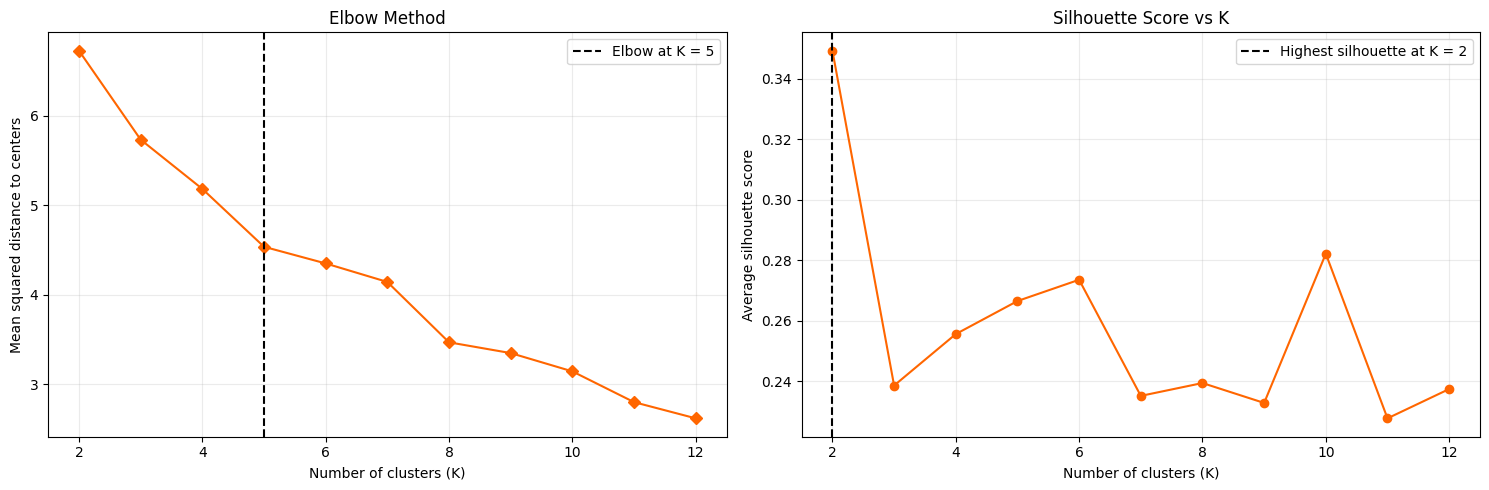

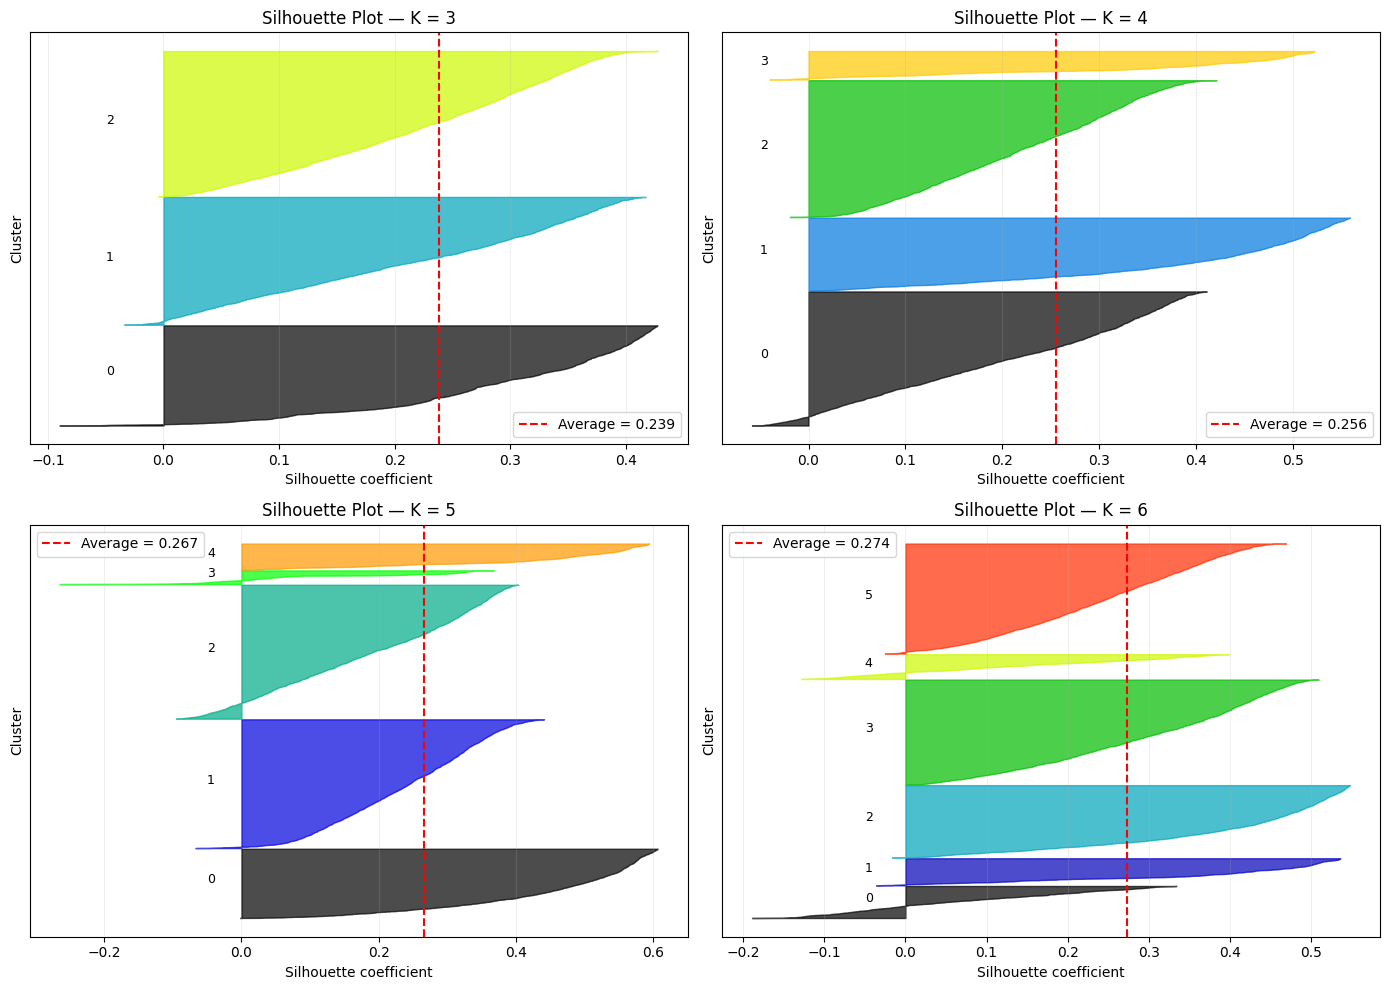

In [37]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# ---------------------------------------------------------
# 1. Select the existing C_Extended_10 features
# ---------------------------------------------------------
features = feature_sets["C_Extended_10"]

feature_idx = [
    scaled_feature_names.index(feature)
    for feature in features
]

X_final = X_scaled[:, feature_idx]

print("Feature set: C_Extended_10")
print("Features:", features)
print("Full dataset shape:", X_final.shape)

# ---------------------------------------------------------
# 2. Sample customers for faster analysis
# ---------------------------------------------------------
rng = np.random.default_rng(42)

sample_size = min(6000, len(X_final))

sample_idx = rng.choice(
    len(X_final),
    size=sample_size,
    replace=False
)

X_s = X_final[sample_idx]

print("Sample shape:", X_s.shape)

# ---------------------------------------------------------
# 3. Fit MiniBatchKMeans for K = 2 to 12
# ---------------------------------------------------------
k_range = list(range(2, 13))

distortions = []
sil_scores = {}
labels_by_k = {}
models_by_k = {}

for k in k_range:
    print(f"Fitting K = {k}")

    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=10,
        max_iter=200
    )

    labels = model.fit_predict(X_s)

    models_by_k[k] = model
    labels_by_k[k] = labels

    # Average squared distance to cluster centers
    distortions.append(model.inertia_ / len(X_s))

    # Silhouette score
    sil_scores[k] = silhouette_score(X_s, labels)

# ---------------------------------------------------------
# 4. Find elbow using perpendicular distance to the line
# ---------------------------------------------------------
def find_elbow(ks, ys):
    x = np.asarray(ks, dtype=float)
    y = np.asarray(ys, dtype=float)

    # Normalize both axes
    x = (x - x.min()) / (x.max() - x.min())
    y = (y - y.min()) / (y.max() - y.min())

    # Perpendicular distance from each point to endpoint line
    start = np.array([x[0], y[0]])
    end = np.array([x[-1], y[-1]])
    line = end - start

    points = np.column_stack((x, y))

    distances = np.abs(
        line[0] * (start[1] - points[:, 1])
        - (start[0] - points[:, 0]) * line[1]
    ) / np.linalg.norm(line)

    # Exclude the endpoints
    distances[0] = 0
    distances[-1] = 0

    return ks[int(np.argmax(distances))]


elbow_k = find_elbow(k_range, distortions)
best_silhouette_k = max(sil_scores, key=sil_scores.get)

print("\nElbow K:", elbow_k)
print("Highest silhouette K:", best_silhouette_k)

# Show numerical results
import pandas as pd

results_df = pd.DataFrame({
    "K": k_range,
    "Distortion": distortions,
    "Silhouette": [sil_scores[k] for k in k_range]
})

display(results_df.round(4))

# ---------------------------------------------------------
# 5. Elbow plot and silhouette comparison
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(
    k_range, distortions,
    marker="D", color="#ff6600"
)
axes[0].axvline(
    elbow_k, color="black", linestyle="--",
    label=f"Elbow at K = {elbow_k}"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Mean squared distance to centers")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    list(sil_scores.keys()),
    list(sil_scores.values()),
    marker="o", color="#ff6600"
)
axes[1].axvline(
    best_silhouette_k, color="black", linestyle="--",
    label=f"Highest silhouette at K = {best_silhouette_k}"
)
axes[1].set_title("Silhouette Score vs K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Average silhouette score")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. Silhouette plots for K = 3, 4, 5, 6
# ---------------------------------------------------------
k_to_plot = [3, 4, 5, 6]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, k in zip(axes.ravel(), k_to_plot):

    labels = labels_by_k[k]

    sample_sil = silhouette_samples(X_s, labels)
    avg = sil_scores[k]

    y_lower = 10

    for cluster_id in range(k):
        vals = np.sort(sample_sil[labels == cluster_id])

        y_upper = y_lower + len(vals)

        color = cm.nipy_spectral(cluster_id / k)

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            vals,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )

        ax.text(
            -0.05,
            y_lower + len(vals) / 2,
            str(cluster_id),
            fontsize=9
        )

        y_lower = y_upper + 10

    ax.axvline(
        avg, color="red", linestyle="--",
        label=f"Average = {avg:.3f}"
    )

    ax.set_title(f"Silhouette Plot — K = {k}")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_ylabel("Cluster")
    ax.set_yticks([])
    ax.legend()
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


Selected features: ['Recency', 'Sale_Frequency', 'Monthly_Spending_Mean', 'average_discount_rate', 'Average_Unit_Price']
Full dataset shape: (1283346, 5)
Sample size: 6000
Fitting K = 2
Fitting K = 3
Fitting K = 4
Fitting K = 5
Fitting K = 6
Fitting K = 7
Fitting K = 8
Fitting K = 9
Fitting K = 10
Fitting K = 11
Fitting K = 12

Estimated elbow K: 5
Highest silhouette K: 2


,K,Distortion,Silhouette
0,2,3.7901,0.2397
1,3,3.1999,0.2290
2,4,2.5740,0.2363
3,5,2.3096,0.2296
4,6,2.1177,0.2324
5,7,2.0224,0.1990
6,8,1.9392,0.1974
7,9,1.7396,0.1870
8,10,1.6693,0.1942
9,11,1.5991,0.1814


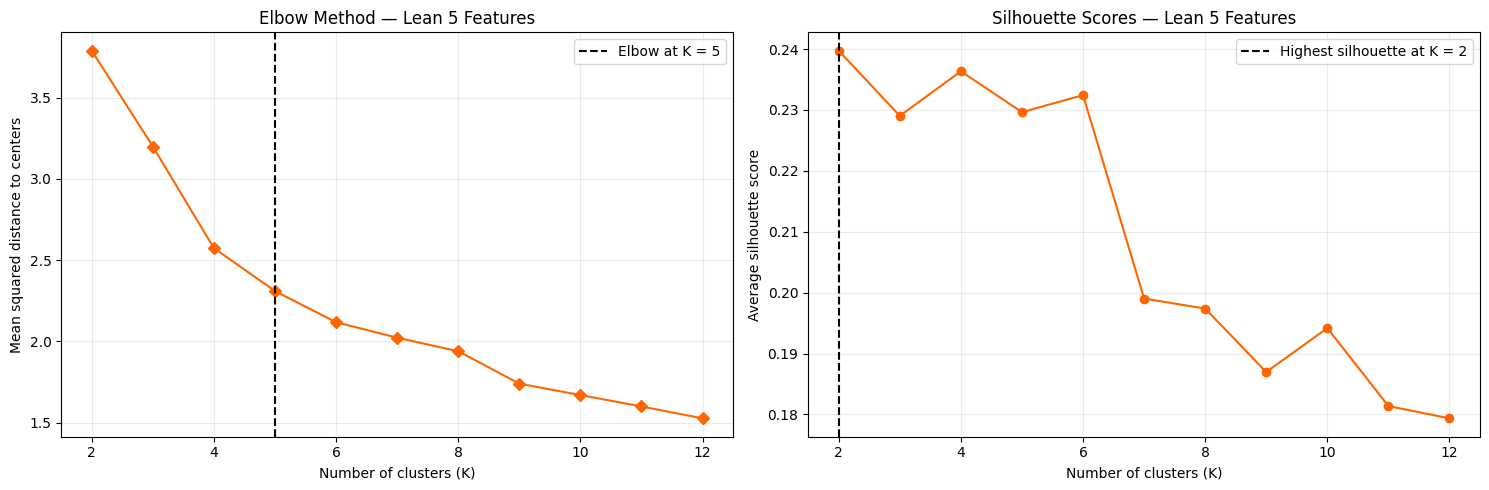

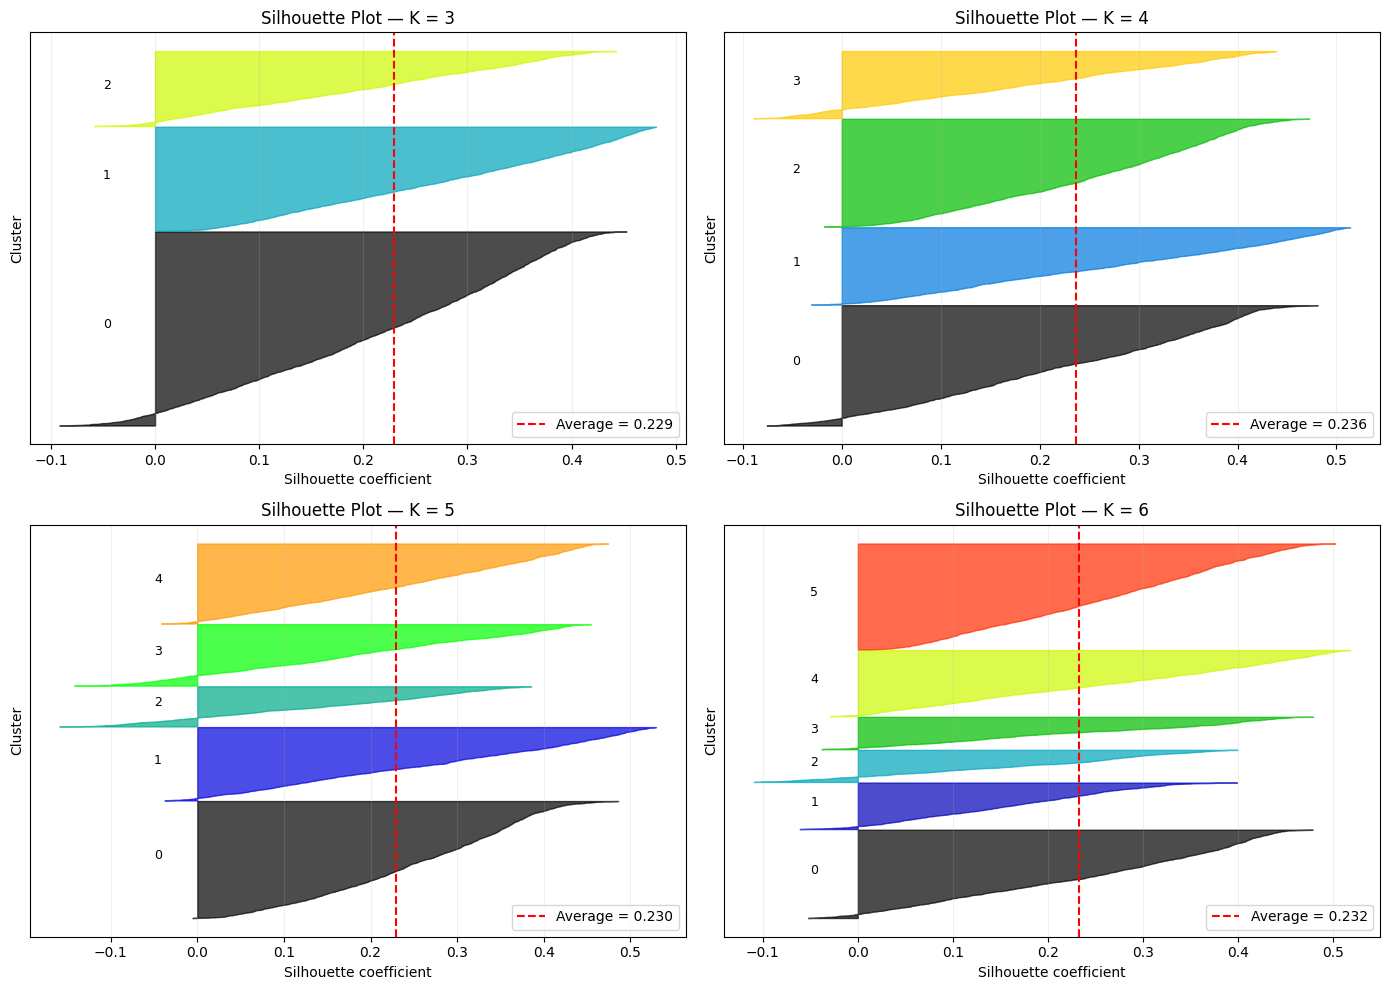

In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# ---------------------------------------------------------
# 1. Select the lean 5-feature set
# ---------------------------------------------------------
selected_features = [
    "Recency",
    "Sale_Frequency",
    "Monthly_Spending_Mean",
    "average_discount_rate",
    "Average_Unit_Price"
]

feature_idx = [
    scaled_feature_names.index(feature)
    for feature in selected_features
]

# Extract the selected columns from your existing scaled matrix
X_final = X_scaled[:, feature_idx]

print("Selected features:", selected_features)
print("Full dataset shape:", X_final.shape)

# ---------------------------------------------------------
# 2. Sample customers for faster analysis
# ---------------------------------------------------------
rng = np.random.default_rng(42)

sample_size = min(6000, len(X_final))

sample_idx = rng.choice(
    len(X_final),
    size=sample_size,
    replace=False
)

X_s = X_final[sample_idx]

print("Sample size:", X_s.shape[0])

# ---------------------------------------------------------
# 3. Fit MiniBatchKMeans for K = 2 to 12
# ---------------------------------------------------------
k_range = list(range(2, 13))

distortions = []
sil_scores = {}
labels_by_k = {}
models_by_k = {}

for k in k_range:
    print(f"Fitting K = {k}")

    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=10,
        max_iter=200
    )

    labels = model.fit_predict(X_s)

    models_by_k[k] = model
    labels_by_k[k] = labels

    # Average squared distance to cluster centers
    distortions.append(model.inertia_ / len(X_s))

    # Average silhouette score
    sil_scores[k] = silhouette_score(X_s, labels)

# ---------------------------------------------------------
# 4. Automatically estimate the elbow
# ---------------------------------------------------------
def find_elbow(ks, ys):
    x = np.asarray(ks, dtype=float)
    y = np.asarray(ys, dtype=float)

    # Normalize both axes
    x = (x - x.min()) / (x.max() - x.min())
    y = (y - y.min()) / (y.max() - y.min())

    start = np.array([x[0], y[0]])
    end = np.array([x[-1], y[-1]])
    line = end - start

    points = np.column_stack((x, y))

    distances = np.abs(
        line[0] * (start[1] - points[:, 1])
        - (start[0] - points[:, 0]) * line[1]
    ) / np.linalg.norm(line)

    # Exclude endpoints
    distances[0] = 0
    distances[-1] = 0

    return ks[int(np.argmax(distances))]


elbow_k = find_elbow(k_range, distortions)
best_silhouette_k = max(sil_scores, key=sil_scores.get)

print("\nEstimated elbow K:", elbow_k)
print("Highest silhouette K:", best_silhouette_k)

results_df = pd.DataFrame({
    "K": k_range,
    "Distortion": distortions,
    "Silhouette": [sil_scores[k] for k in k_range]
})

display(results_df.round(4))

# ---------------------------------------------------------
# 5. Elbow plot and silhouette comparison
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(
    k_range, distortions,
    marker="D", color="#ff6600"
)
axes[0].axvline(
    elbow_k, color="black", linestyle="--",
    label=f"Elbow at K = {elbow_k}"
)
axes[0].set_title("Elbow Method — Lean 5 Features")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Mean squared distance to centers")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    list(sil_scores.keys()),
    list(sil_scores.values()),
    marker="o", color="#ff6600"
)
axes[1].axvline(
    best_silhouette_k, color="black", linestyle="--",
    label=f"Highest silhouette at K = {best_silhouette_k}"
)
axes[1].set_title("Silhouette Scores — Lean 5 Features")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Average silhouette score")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. Silhouette plots for K = 3, 4, 5, 6
# ---------------------------------------------------------
k_to_plot = [3, 4, 5, 6]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, k in zip(axes.ravel(), k_to_plot):
    labels = labels_by_k[k]
    sample_sil = silhouette_samples(X_s, labels)
    avg = sil_scores[k]

    y_lower = 10

    for cluster_id in range(k):
        vals = np.sort(sample_sil[labels == cluster_id])
        y_upper = y_lower + len(vals)

        color = cm.nipy_spectral(cluster_id / k)

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            vals,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )

        ax.text(
            -0.05,
            y_lower + len(vals) / 2,
            str(cluster_id),
            fontsize=9
        )

        y_lower = y_upper + 10

    ax.axvline(
        avg, color="red", linestyle="--",
        label=f"Average = {avg:.3f}"
    )

    ax.set_title(f"Silhouette Plot — K = {k}")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_ylabel("Cluster")
    ax.set_yticks([])
    ax.legend()
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


In [39]:
import joblib
from sklearn.cluster import KMeans

final_feats = ['Recency','Sale_Frequency','Monthly_Spending_Mean',
               'average_discount_rate','Average_Unit_Price']
X_final = X_scaled[:, idx_of(final_feats)]

final_model = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_final)
customer_df['Cluster'] = final_model.labels_

joblib.dump(preprocessor, '/content/drive/MyDrive/ML_Project_2.0/preprocessor.joblib')
joblib.dump(final_model,  '/content/drive/MyDrive/ML_Project_2.0/kmeans_k4.joblib')
joblib.dump({'features': final_feats, 'all_scaled_names': scaled_feature_names},
            '/content/drive/MyDrive/ML_Project_2.0/model_meta.joblib')

['/content/drive/MyDrive/ML_Project_2.0/model_meta.joblib']

In [54]:
km_full = KMeans(n_clusters=4, n_init=5, random_state=42).fit(X_final)
print("ARI vs full K-Means:", adjusted_rand_score(customer_df['Cluster'], km_full.labels_))

ARI vs full K-Means: 0.9937332543207577


In [55]:
import pickle
import numpy as np
import pandas as pd
import sklearn

final_feats = ['Recency', 'Sale_Frequency', 'Monthly_Spending_Mean',
               'average_discount_rate', 'Average_Unit_Price']

# 1. Fitted scalers for the 5 model features (taken from your ColumnTransformer)
log_scaler  = preprocessor.named_transformers_['log_features'].named_steps['scale']
rate_scaler = preprocessor.named_transformers_['rates'].named_steps['scale']

scaling = {}
for i, f in enumerate(log_features):
    scaling[f] = {"log": True,  "mean": float(log_scaler.mean_[i]),  "scale": float(log_scaler.scale_[i])}
for i, f in enumerate(rate_features):
    scaling[f] = {"log": False, "mean": float(rate_scaler.mean_[i]), "scale": float(rate_scaler.scale_[i])}
scaling = {f: scaling[f] for f in final_feats}

# 2. Profile features used for the "reason" (all numeric features from the dictionary)
profile_candidates = [
    'Recency', 'Frequency', 'Sale_Frequency', 'Unique_Products', 'Net_Monetary',
    'Gross_Monetary', 'Customer_Lifetime', 'Average_Purchase_Interval',
    'Total_Quantity', 'Average_Unit_Price', 'average_discount_rate',
    'products_with_base_price', 'products_with_discount', 'Return_Count',
    'Returned_Quantity', 'Return_Value', 'Monthly_Spending_Mean',
    'Monthly_Spending_Std', 'Spending_Trend', 'average_order_value', 'Return_Rate'
]
profile_features = [c for c in profile_candidates if c in customer_df.columns]

data = customer_df[profile_features].replace([np.inf, -np.inf], np.nan)
cluster_medians = data.groupby(customer_df['Cluster']).median()
overall_median  = data.median()
overall_iqr     = data.quantile(0.75) - data.quantile(0.25)

sizes = customer_df['Cluster'].value_counts().sort_index()

# 3. Benchmarks (K sweep from cell 36, which used your final 5 features)
benchmarks = {"stability": {"ari_minibatch_vs_full_kmeans": 0.994,
                            "ari_full_kmeans_across_seeds": [0.993, 0.994, 0.999]}}
try:
    benchmarks["k_values"]   = [int(k) for k in k_range]
    benchmarks["silhouette"] = [float(np.mean(sil_scores[k])) for k in k_range]
    benchmarks["distortion"] = [float(d) for d in distortions]
except NameError:
    print("K-sweep variables not found; rerun cell 36 first, then run this again")

# 4. Bundle everything
artifacts = {
    "sklearn_version": sklearn.__version__,
    "model": final_model,
    "features": final_feats,
    "scaling": scaling,
    "segment_names": {int(k): v for k, v in segment_names.items()},
    "profile_features": profile_features,
    "cluster_medians": cluster_medians,
    "overall_median": overall_median,
    "overall_iqr": overall_iqr,
    "cluster_sizes": {int(c): int(sizes[c]) for c in sizes.index},
    "total_customers": int(len(customer_df)),
    "analysis_date": "2026-01-01",   # for 31 Dec 2025 data, subject to the check below
    "benchmarks": benchmarks,
}

with open("artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)

# 5. Self-test: reload and confirm it reproduces your existing cluster labels
with open("artifacts.pkl", "rb") as f:
    art = pickle.load(f)

def scale5(df, art):
    cols = []
    for f in art["features"]:
        s = art["scaling"][f]
        v = df[f].astype(float).values
        if s["log"]:
            v = np.log1p(v)
        cols.append((v - s["mean"]) / s["scale"])
    return np.column_stack(cols)

check = customer_df.sample(5000, random_state=0)
pred = art["model"].predict(scale5(check, art))
print("Match with existing Cluster labels:", (pred == check["Cluster"].values).mean())
print("sklearn version:", art["sklearn_version"])
print("Segment names:", art["segment_names"])

Match with existing Cluster labels: 1.0
sklearn version: 1.6.1
Segment names: {0: 'Loyal High-Value', 1: 'Inactive Moderate-Spending Customers', 2: 'Discount-Driven Regulars', 3: 'Lapsed Low-Spending Customers'}


In [56]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Rebuild X_final here so this cell doesn't depend on which cell ran last
final_feats = ['Recency','Sale_Frequency','Monthly_Spending_Mean',
               'average_discount_rate','Average_Unit_Price']
X_final = X_scaled[:, idx_of(final_feats)]

# 1. Is the MiniBatch solution worse than the full-data one?
mb_inertia = -final_model.score(X_final)
print("MiniBatch inertia  :", round(mb_inertia))
print("Full KMeans inertia:", round(km_full.inertia_))
print(f"Gap: {(mb_inertia - km_full.inertia_) / km_full.inertia_ * 100:.2f}%")
print("ARI MiniBatch vs full KMeans:",
      round(adjusted_rand_score(customer_df['Cluster'], km_full.labels_), 3))

# 2. Is full-data KMeans reproducible by itself?
runs = {s: KMeans(n_clusters=4, n_init=3, random_state=s).fit(X_final) for s in [1, 2, 3]}
for a, b in [(1, 2), (1, 3), (2, 3)]:
    print(f"ARI full KMeans seed {a} vs {b}:",
          round(adjusted_rand_score(runs[a].labels_, runs[b].labels_), 3))

MiniBatch inertia  : 3285206
Full KMeans inertia: 3285214
Gap: -0.00%
ARI MiniBatch vs full KMeans: 0.994
ARI full KMeans seed 1 vs 2: 0.993
ARI full KMeans seed 1 vs 3: 0.994
ARI full KMeans seed 2 vs 3: 0.999


In [42]:
customer_df['Has_Returned']  = (customer_df['Return_Count'] > 0).astype(int)
customer_df['Is_One_Time']   = (customer_df['Sale_Frequency'] == 1).astype(int)
customer_df['Trend_Up']      = (customer_df['Spending_Trend'] > 0).astype(int)
customer_df['Deep_Discount'] = (customer_df['average_discount_rate'] >= 0.4).astype(int)

display((customer_df.groupby('Cluster')[['Has_Returned','Is_One_Time',
                                         'Trend_Up','Deep_Discount']].mean() * 100).round(1))

,Has_Returned,Is_One_Time,Trend_Up,Deep_Discount
Cluster,,,,
0,24.0,0.5,48.8,0.2
1,10.9,34.8,31.6,0.1
2,8.1,41.2,27.2,45.0
3,7.0,47.0,25.7,0.2


In [43]:
profile_cols = ['Recency','Sale_Frequency','Net_Monetary','Monthly_Spending_Mean',
                'average_discount_rate','Average_Unit_Price','Unique_Products',
                'Customer_Lifetime','Spending_Trend','Return_Rate']
profile = customer_df.groupby('Cluster')[profile_cols].median()
profile.insert(0, 'Customers', customer_df['Cluster'].value_counts().sort_index())
profile.insert(1, 'Pct', (profile['Customers'] / len(customer_df) * 100).round(1))
display(profile.round(2))

# Favorite day / month per segment
display(pd.crosstab(customer_df['Cluster'], customer_df['Favorite_Shopping_Day_in_week'], normalize='index').round(3))
display(pd.crosstab(customer_df['Cluster'], customer_df['Favorite_Shopping_month_in_year'], normalize='index').round(3))

,Customers,Pct,Recency,Sale_Frequency,Net_Monetary,Monthly_Spending_Mean,average_discount_rate,Average_Unit_Price,Unique_Products,Customer_Lifetime,Spending_Trend,Return_Rate
Cluster,,,,,,,,,,,,
0,456423,35.6,80.0,5.0,322.65,71.75,0.12,50.67,7.0,578.0,-0.22,0.0
1,359975,28.0,279.0,2.0,166.32,91.75,0.00,59.52,3.0,146.0,0.00,0.0
2,206779,16.1,164.0,2.0,66.36,38.96,0.37,47.85,2.0,90.0,0.00,0.0
3,260169,20.3,279.0,2.0,50.55,35.97,0.00,33.40,2.0,43.0,0.00,0.0


Favorite_Shopping_Day_in_week,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
Cluster,,,,,,,
0,0.142,0.141,0.259,0.239,0.073,0.073,0.073
1,0.144,0.142,0.236,0.215,0.093,0.088,0.081
2,0.152,0.161,0.236,0.213,0.077,0.072,0.088
3,0.156,0.153,0.237,0.211,0.088,0.080,0.075


Favorite_Shopping_month_in_year,April,August,December,February,January,July,June,March,May,November,October,September
Cluster,,,,,,,,,,,,
0,0.078,0.053,0.333,0.068,0.079,0.031,0.028,0.115,0.043,0.041,0.061,0.071
1,0.119,0.073,0.145,0.051,0.061,0.062,0.064,0.105,0.075,0.069,0.093,0.083
2,0.024,0.018,0.650,0.005,0.059,0.004,0.003,0.077,0.029,0.023,0.021,0.088
3,0.105,0.083,0.146,0.117,0.126,0.060,0.047,0.080,0.062,0.050,0.071,0.053


,Customers,Percentage
Cluster,,
0,456423,35.57
1,359975,28.05
2,206779,16.11
3,260169,20.27


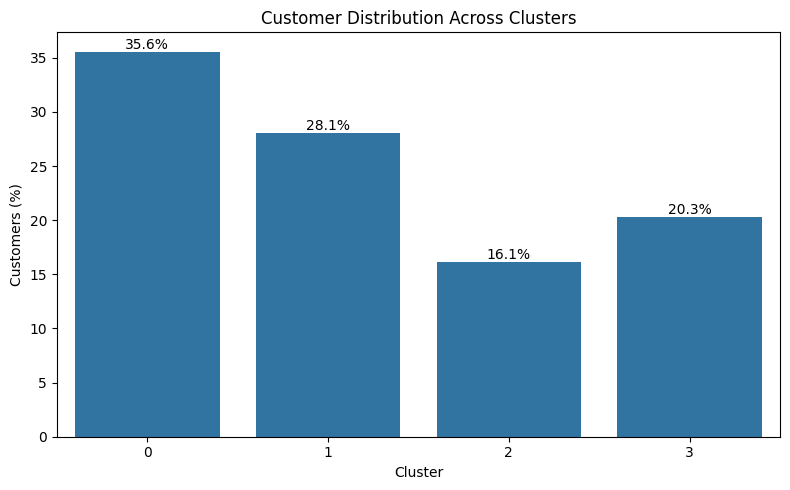

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check cluster distribution
cluster_counts = customer_df['Cluster'].value_counts().sort_index()

cluster_summary = pd.DataFrame({
    'Customers': cluster_counts,
    'Percentage': (cluster_counts / len(customer_df) * 100).round(2)
})

display(cluster_summary)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=cluster_summary.index.astype(str),
    y=cluster_summary['Percentage']
)

plt.title('Customer Distribution Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Customers (%)')

for i, value in enumerate(cluster_summary['Percentage']):
    ax.text(i, value, f'{value:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

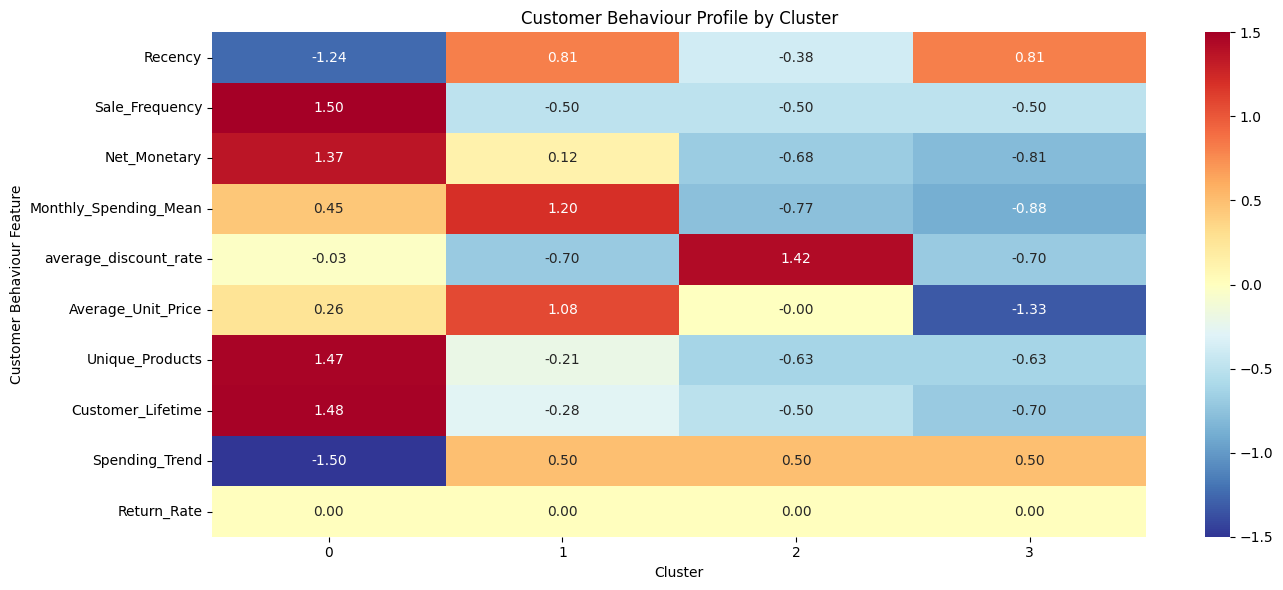

Actual median values:


,Recency,Sale_Frequency,Net_Monetary,Monthly_Spending_Mean,average_discount_rate,Average_Unit_Price,Unique_Products,Customer_Lifetime,Spending_Trend,Return_Rate
Cluster,,,,,,,,,,
0,80.0,5.0,322.65,71.75,0.12,50.67,7.0,578.0,-0.22,0.0
1,279.0,2.0,166.32,91.75,0.00,59.52,3.0,146.0,0.00,0.0
2,164.0,2.0,66.36,38.96,0.37,47.85,2.0,90.0,0.00,0.0
3,279.0,2.0,50.55,35.97,0.00,33.40,2.0,43.0,0.00,0.0


In [45]:
# Use original, interpretable customer data
behavior_cols = [
    'Recency',
    'Sale_Frequency',
    'Net_Monetary',
    'Monthly_Spending_Mean',
    'average_discount_rate',
    'Average_Unit_Price',
    'Unique_Products',
    'Customer_Lifetime',
    'Spending_Trend',
    'Return_Rate'
]

behavior_cols = [
    col for col in behavior_cols
    if col in customer_df.columns
]

cluster_medians = customer_df.groupby('Cluster')[behavior_cols].median()

# Standardize each feature across cluster medians for the heatmap
heatmap_data = (
    cluster_medians - cluster_medians.mean()
) / cluster_medians.std().replace(0, 1)

plt.figure(figsize=(14, 6))
sns.heatmap(
    heatmap_data.T,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu_r',
    center=0
)

plt.title('Customer Behaviour Profile by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Customer Behaviour Feature')
plt.tight_layout()
plt.show()

print("Actual median values:")
display(cluster_medians.round(2))

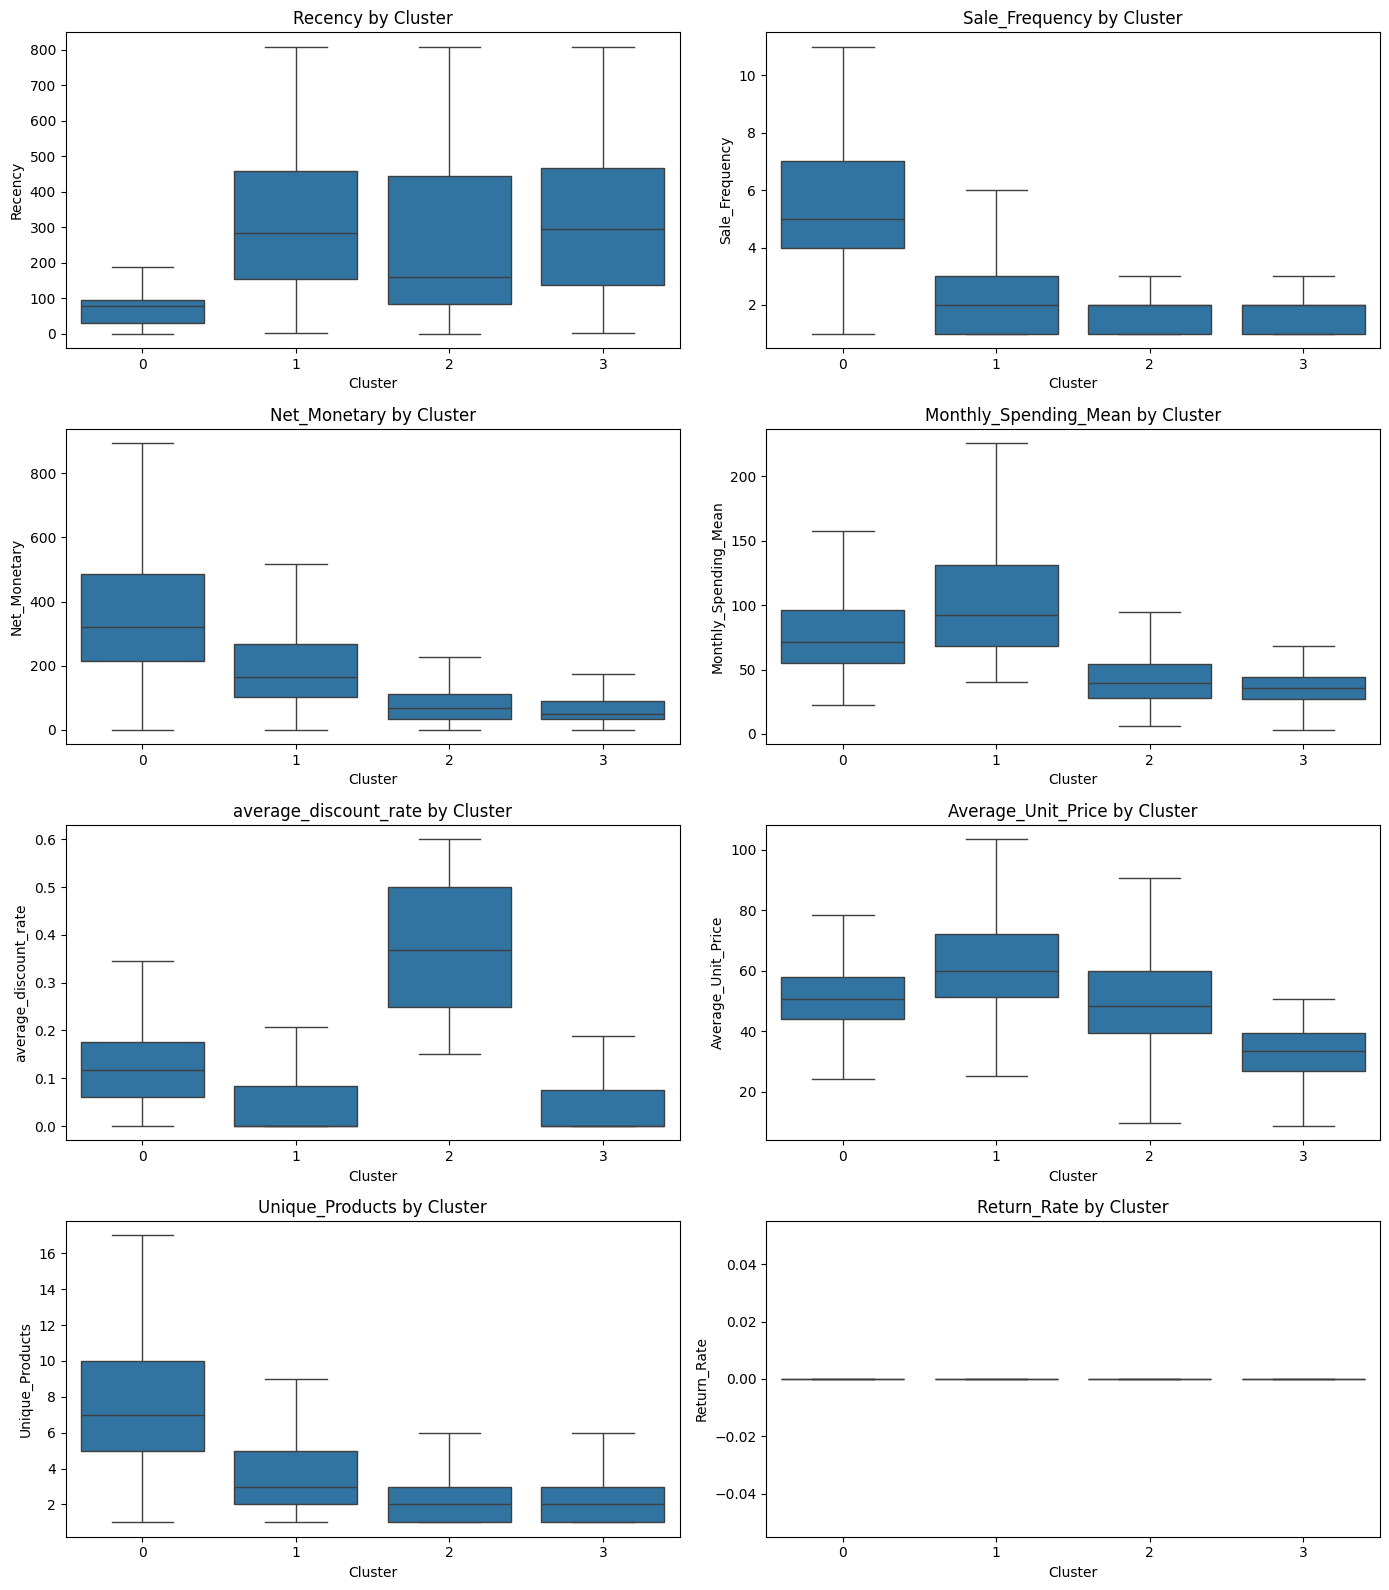

In [46]:
plot_cols = [
    'Recency',
    'Sale_Frequency',
    'Net_Monetary',
    'Monthly_Spending_Mean',
    'average_discount_rate',
    'Average_Unit_Price',
    'Unique_Products',
    'Return_Rate'
]

plot_cols = [c for c in plot_cols if c in customer_df.columns]

# Sample for faster plotting; cluster profiles still use the full dataset
plot_df = customer_df.sample(
    n=min(20000, len(customer_df)),
    random_state=42
).copy()

ncols = 2
nrows = int(np.ceil(len(plot_cols) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(14, 4 * nrows)
)
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, plot_cols):
    sns.boxplot(
        data=plot_df,
        x='Cluster',
        y=col,
        showfliers=False,
        ax=ax
    )
    ax.set_title(f'{col} by Cluster')
    ax.set_xlabel('Cluster')
    ax.set_ylabel(col)

for ax in axes[len(plot_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [47]:
med = customer_df.groupby('Cluster')[['Sale_Frequency','average_discount_rate']].median()

loyal    = med['Sale_Frequency'].idxmax()
one_time = med['Sale_Frequency'].idxmin()
rest     = med.drop([loyal, one_time])
discount = rest['average_discount_rate'].idxmax()
lapsed   = rest['average_discount_rate'].idxmin()

segment_names = {loyal: 'Loyal High-Value', one_time: 'One-Time Low-Basket',
                 discount: 'Discount-Driven Regulars', lapsed: 'Lapsed Full-Price Repeaters'}
print(segment_names)    # check this against your profile table before trusting it

customer_df['Segment'] = customer_df['Cluster'].map(segment_names)

print(customer_df.head)

{np.int32(0): 'Loyal High-Value', np.int32(1): 'One-Time Low-Basket', np.int32(2): 'Discount-Driven Regulars', np.int32(3): 'Lapsed Full-Price Repeaters'}
<bound method NDFrame.head of          Customer ID  Last_Purchase_Date  Recency  Frequency  \
0                  1 2024-12-07 16:00:00      102          5   
1                  2 2025-02-13 17:33:00       34          4   
2                  3 2024-05-26 20:35:00      297          3   
3                  4 2023-10-09 12:06:00      527          2   
4                  5 2024-11-27 17:42:00      112         11   
...              ...                 ...      ...        ...   
1283341      1643293 2023-09-08 14:58:00      558          1   
1283342      1643294 2024-10-19 12:03:00      151          2   
1283343      1643297 2024-11-27 16:20:00      112          2   
1283344      1643302 2024-12-25 15:35:00       84          1   
1283345      1643306 2023-12-12 09:20:00      463          1   

        first_Purchase_Date  Unique_Products  

In [48]:
print(customer_df.groupby('Segment').size())

Segment
Discount-Driven Regulars       206779
Lapsed Full-Price Repeaters    260169
Loyal High-Value               456423
One-Time Low-Basket            359975
dtype: int64


26 features: ['Recency', 'Frequency', 'Unique_Products', 'Net_Monetary', 'Customer_Lifetime', 'Average_Purchase_Interval', 'Gross_Monetary', 'Total_Quantity', 'Average_Unit_Price', 'average_discount_rate', 'products_with_base_price', 'products_with_discount', 'Return_Count', 'Returned_Quantity', 'Return_Value', 'Monthly_Spending_Mean', 'Monthly_Spending_Std', 'Spending_Trend', 'Is_One_Time_Customer', 'Sale_Frequency', 'average_order_value', 'Return_Rate', 'Has_Returned', 'Is_One_Time', 'Trend_Up', 'Deep_Discount']


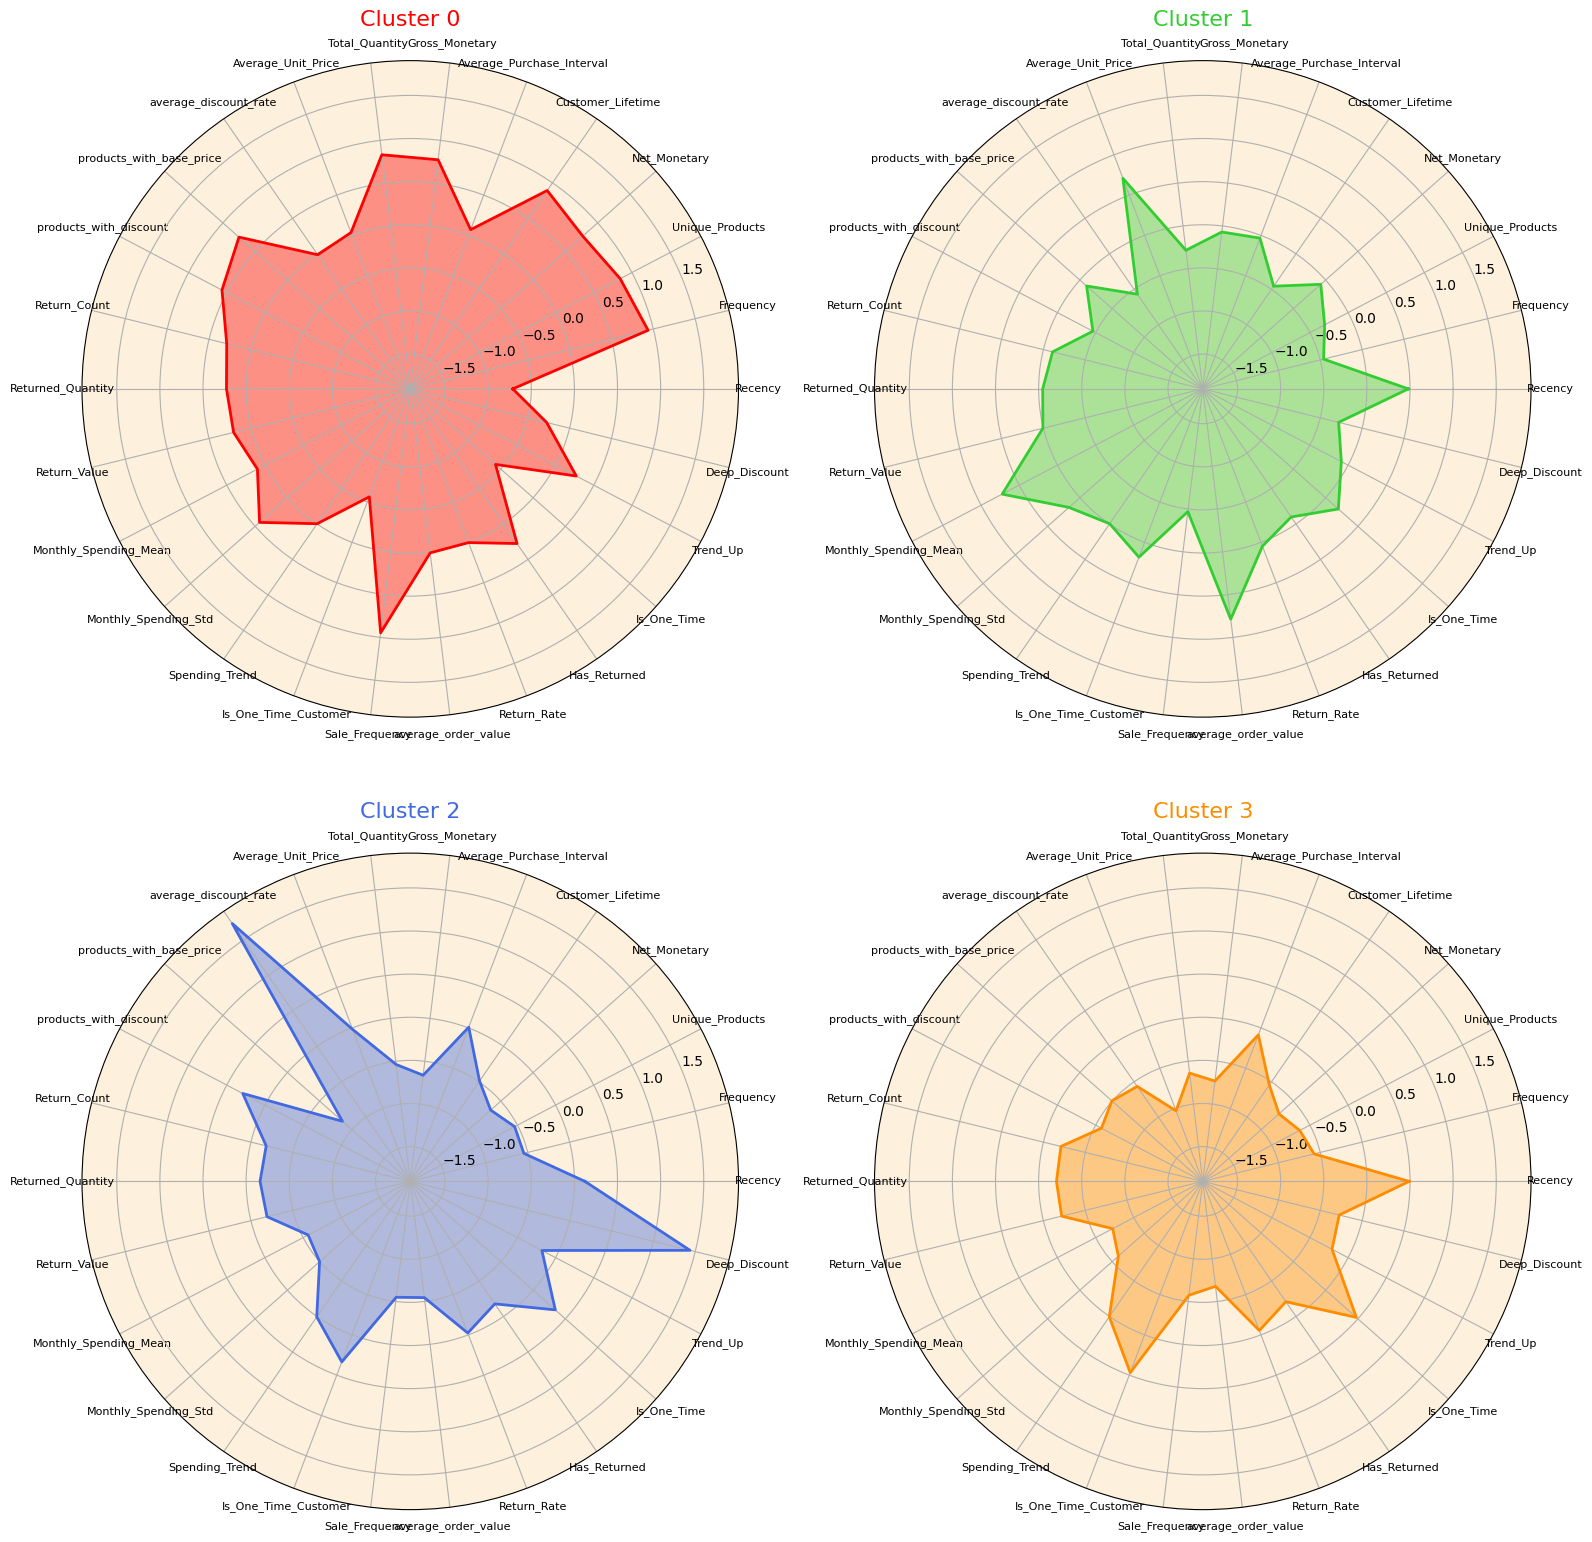

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Pick the features: all numeric columns except IDs/labels
exclude = ["Customer ID", "Cluster"]
radar_features = [
    c for c in customer_df.select_dtypes(include="number").columns
    if c not in exclude
]
print(f"{len(radar_features)} features:", radar_features)

# 2. Z-score every feature across ALL customers, then average per cluster
data = customer_df[radar_features].replace([np.inf, -np.inf], np.nan)
z = (data - data.mean()) / data.std().replace(0, 1)
z["Cluster"] = customer_df["Cluster"].values
cluster_z = z.groupby("Cluster")[radar_features].mean()   # rows = clusters

# 3. Radar plot, one per cluster
def plot_cluster_radars(cluster_z, ncols=2, colors=None):
    clusters = cluster_z.index.tolist()
    feats = cluster_z.columns.tolist()
    n = len(feats)
    angles = np.linspace(0, 2 * np.pi, n, endpoint=False).tolist()
    angles += angles[:1]                                   # close the polygon

    colors = colors or ["red", "limegreen", "royalblue", "darkorange",
                        "purple", "teal", "brown", "gray"]
    nrows = int(np.ceil(len(clusters) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 8 * nrows),
                             subplot_kw=dict(polar=True))
    axes = np.array(axes).reshape(-1)

    lim = np.abs(cluster_z.values).max() * 1.1             # same scale for all clusters

    for ax, cl, col in zip(axes, clusters, colors):
        vals = cluster_z.loc[cl].tolist()
        vals += vals[:1]
        ax.plot(angles, vals, color=col, linewidth=2)
        ax.fill(angles, vals, color=col, alpha=0.4)
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(feats, fontsize=8)
        ax.set_ylim(-lim, lim)
        ax.set_facecolor("#fdf0dc")
        ax.set_title(f"Cluster {cl}", color=col, fontsize=16, pad=25)

    for ax in axes[len(clusters):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

plot_cluster_radars(cluster_z)

In [50]:
# 1. The raw mapping: cluster number -> segment name
print("Cluster -> Segment name")
for cluster_id, name in sorted(segment_names.items()):
    print(f"  Cluster {cluster_id}: {name}")

# 2. The same mapping beside each cluster's profile, so you can sanity-check it
check_cols = ['Recency', 'Sale_Frequency', 'Net_Monetary',
              'Monthly_Spending_Mean', 'average_discount_rate',
              'Average_Unit_Price', 'Customer_Lifetime']

summary = customer_df.groupby('Cluster')[check_cols].median()
summary.insert(0, 'Segment', summary.index.map(segment_names))
summary.insert(1, 'Customers', customer_df['Cluster'].value_counts().sort_index())
summary['One_Time_%'] = (customer_df.groupby('Cluster')['Sale_Frequency']
                         .apply(lambda s: (s == 1).mean() * 100)).round(1)

display(summary.round(2))

Cluster -> Segment name
  Cluster 0: Loyal High-Value
  Cluster 1: One-Time Low-Basket
  Cluster 2: Discount-Driven Regulars
  Cluster 3: Lapsed Full-Price Repeaters


,Segment,Customers,Recency,Sale_Frequency,Net_Monetary,Monthly_Spending_Mean,average_discount_rate,Average_Unit_Price,Customer_Lifetime,One_Time_%
Cluster,,,,,,,,,,
0,Loyal High-Value,456423,80.0,5.0,322.65,71.75,0.12,50.67,578.0,0.5
1,One-Time Low-Basket,359975,279.0,2.0,166.32,91.75,0.00,59.52,146.0,34.8
2,Discount-Driven Regulars,206779,164.0,2.0,66.36,38.96,0.37,47.85,90.0,41.2
3,Lapsed Full-Price Repeaters,260169,279.0,2.0,50.55,35.97,0.00,33.40,43.0,47.0


In [51]:

# Verify the profiles of Clusters 1 and 3 before finalizing names

import pandas as pd
import numpy as np

check_columns = [
    "Recency",
    "Sale_Frequency",
    "Net_Monetary",
    "Monthly_Spending_Mean",
    "average_discount_rate",
    "Average_Unit_Price",
    "Customer_Lifetime",
    "Unique_Products",
    "Return_Rate"
]

check_columns = [
    col for col in check_columns
    if col in customer_df.columns
]

# Focus on the two clusters in question
subset = customer_df[
    customer_df["Cluster"].isin([1, 3])
].copy()

# Summarize typical values and variability
summary = subset.groupby("Cluster")[check_columns].agg(
    ["median", "mean"]
).round(2)

print("CLUSTER 1 VS CLUSTER 3: DETAILED PROFILE")
display(summary)

# Inspect purchase-frequency distribution
frequency_distribution = pd.crosstab(
    subset["Cluster"],
    subset["Sale_Frequency"],
    normalize="index"
).mul(100).round(2)

print("\nPURCHASE FREQUENCY DISTRIBUTION (%)")
display(frequency_distribution)

# Inspect discount-rate distribution
discount_distribution = pd.crosstab(
    subset["Cluster"],
    subset["average_discount_rate"],
    normalize="index"
).mul(100).round(2)

print("\nDISCOUNT RATE DISTRIBUTION (%)")
display(discount_distribution)


CLUSTER 1 VS CLUSTER 3: DETAILED PROFILE


Recency        Sale_Frequency       Net_Monetary          \
         median   mean         median  mean       median    mean   
Cluster                                                            
1         279.0  312.1            2.0  2.14       166.32  204.91   
3         279.0  314.1            2.0  1.87        50.55   66.75   

        Monthly_Spending_Mean         average_discount_rate        \
                       median    mean                median  mean   
Cluster                                                             
1                       91.75  111.03                   0.0  0.04   
3                       35.97   37.31                   0.0  0.05   

        Average_Unit_Price        Customer_Lifetime         Unique_Products  \
                    median   mean            median    mean          median   
Cluster                                                                       
1                    59.52  63.57             146.0  195.24             3.0   
3                    33.40  32.78              43.0  172.27             2.0   

              Return_Rate        
         mean      median  mean  
Cluster                          
1        3.46         0.0  0.05  
3        2.11         0.0  0.04


PURCHASE FREQUENCY DISTRIBUTION (%)


Sale_Frequency,1,2,3,4,5,6,7,8,9,10
Cluster,,,,,,,,,,
1,34.80,31.88,21.3,8.96,2.53,0.46,0.07,0.01,0.0,0.0
3,47.01,29.20,16.0,5.86,1.57,0.31,0.05,0.01,0.0,0.0



DISCOUNT RATE DISTRIBUTION (%)


average_discount_rate,0.000000,0.011364,0.011765,0.012500,0.013333,0.014286,0.014706,0.015385,0.015625,0.016667,...,0.423077,0.425000,0.428571,0.435000,0.437500,0.438462,0.450000,0.454545,0.500000,0.600000
Cluster,,,,,,,,,,,,,,,,,,,,,
1,67.24,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.0,0.01,...,0.0,0.0,0.01,0.0,0.01,0.0,0.0,0.0,0.02,0.0
3,71.57,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,...,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.23,0.0


In [52]:

segment_names = {
    0: "Loyal High-Value",
    1: "Inactive Moderate-Spending Customers",
    2: "Discount-Driven Regulars",
    3: "Lapsed Low-Spending Customers"
}

print("Updated customer segment names:")
for cluster_id, name in segment_names.items():
    print(f"Cluster {cluster_id}: {name}")


Updated customer segment names:
Cluster 0: Loyal High-Value
Cluster 1: Inactive Moderate-Spending Customers
Cluster 2: Discount-Driven Regulars
Cluster 3: Lapsed Low-Spending Customers


In [57]:

import pickle

# Load the existing saved artifacts
with open("artifacts.pkl", "rb") as f:
    artifacts = pickle.load(f)

# Update only the segment names
artifacts["segment_names"] = {
    int(cluster_id): name
    for cluster_id, name in segment_names.items()
}

# Save the updated artifact
with open("artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)

# Verify the updated file
with open("artifacts.pkl", "rb") as f:
    updated_artifacts = pickle.load(f)

print("Updated segment names successfully:")
print(updated_artifacts["segment_names"])


Updated segment names successfully:
{0: 'Loyal High-Value', 1: 'Inactive Moderate-Spending Customers', 2: 'Discount-Driven Regulars', 3: 'Lapsed Low-Spending Customers'}


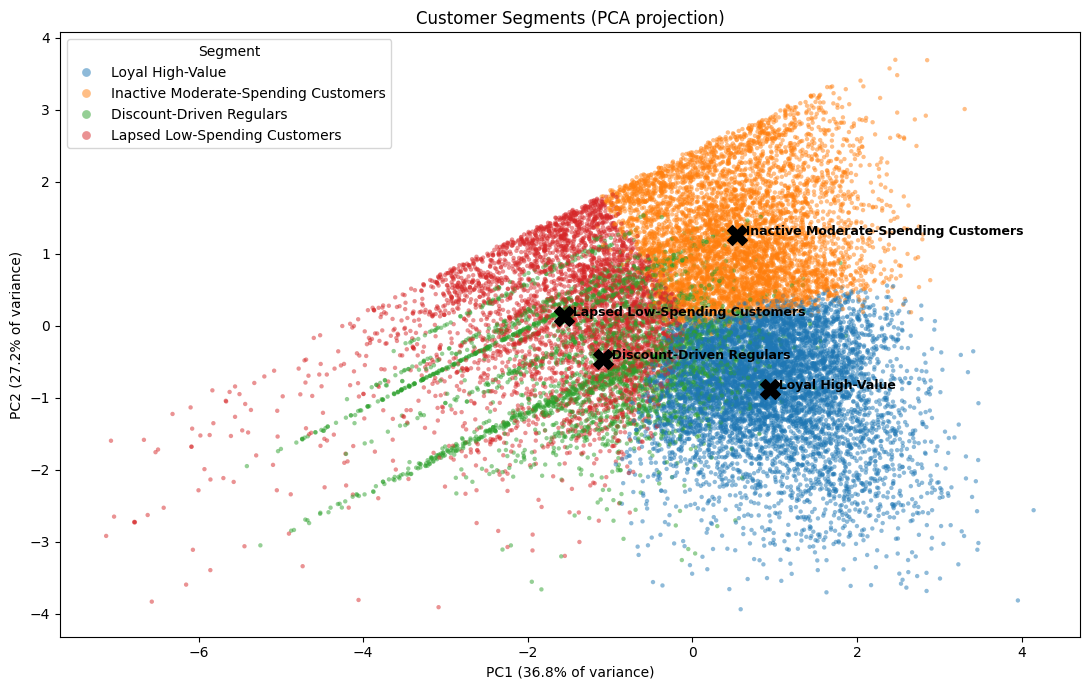

Variance shown in this chart: 64.0%


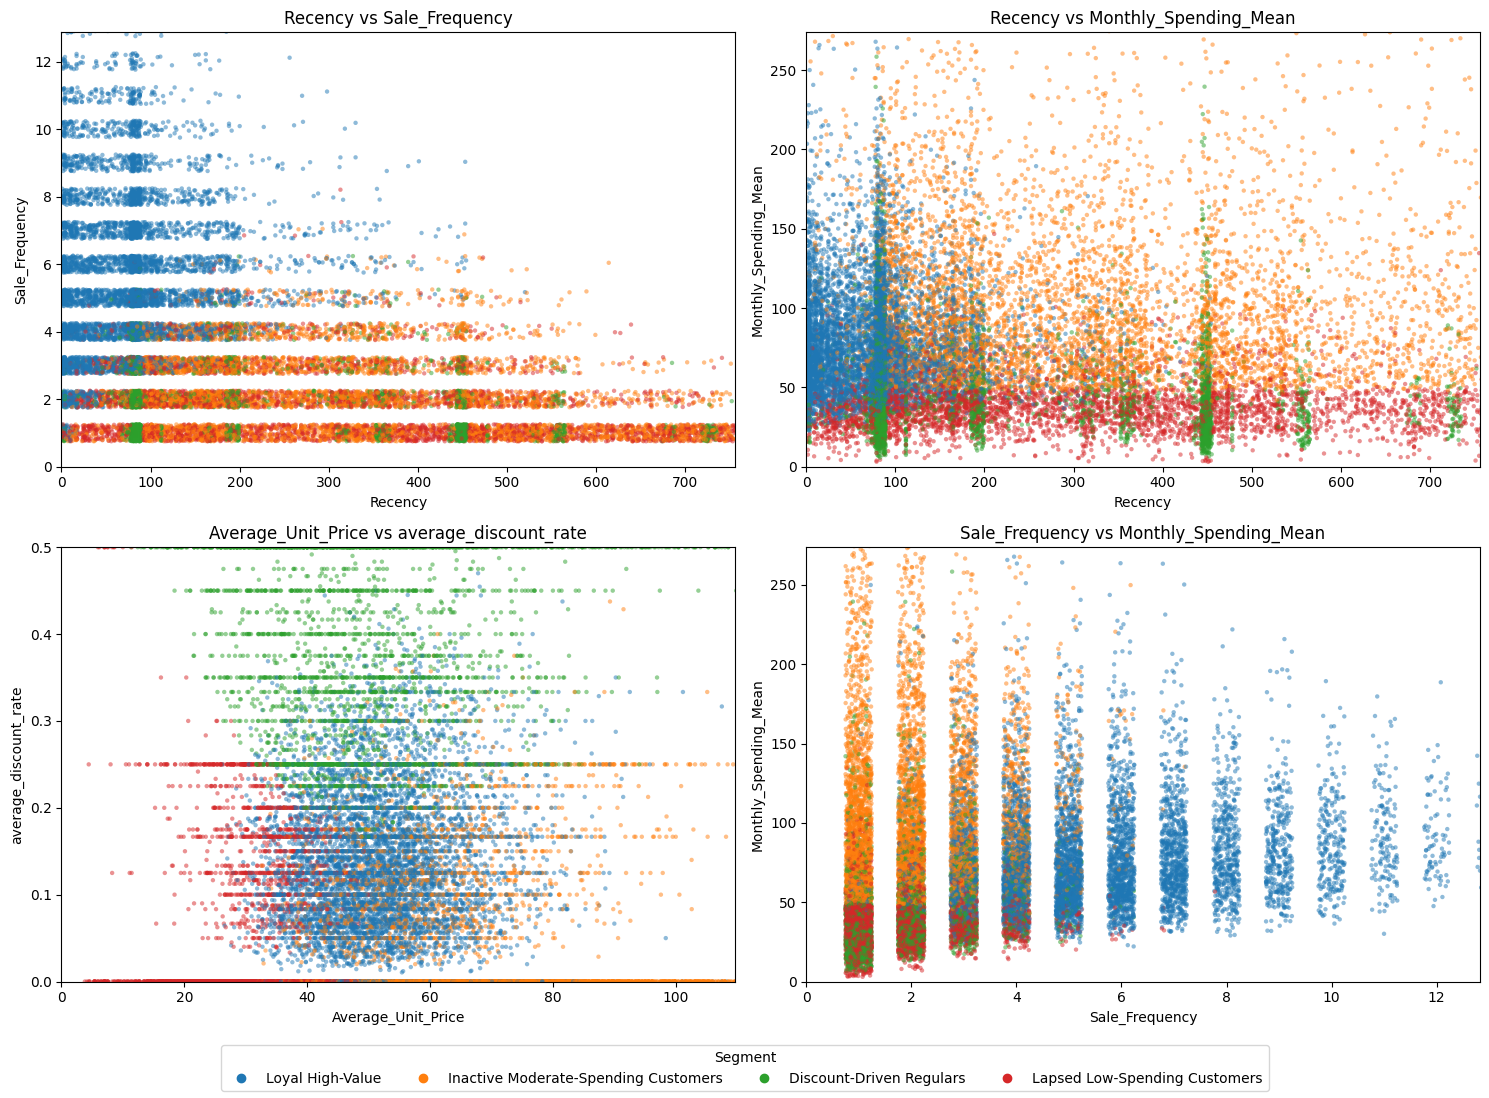

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Re-apply the final names (cell 51 renamed segments after cell 46 had mapped them)
customer_df['Segment'] = customer_df['Cluster'].map(segment_names)

final_feats = ['Recency','Sale_Frequency','Monthly_Spending_Mean',
               'average_discount_rate','Average_Unit_Price']
X_final = X_scaled[:, idx_of(final_feats)]

# Sample customers for plotting (1.28M points would be unreadable)
rng = np.random.default_rng(42)
idx = rng.choice(len(X_final), size=20000, replace=False)
plot_df = customer_df.iloc[idx].copy()

order   = [segment_names[k] for k in sorted(segment_names)]
palette = dict(zip(order, sns.color_palette('tab10', len(order))))

# ---------------------------------------------------------
# Chart 1: PCA scatter (5 model features squeezed into 2 axes)
# ---------------------------------------------------------
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_final[idx])
plot_df['PC1'], plot_df['PC2'] = coords[:, 0], coords[:, 1]
var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Segment', hue_order=order,
                palette=palette, s=10, alpha=0.5, linewidth=0, ax=ax)

centers = plot_df.groupby('Segment')[['PC1', 'PC2']].mean()
ax.scatter(centers['PC1'], centers['PC2'], c='black', marker='X', s=200, zorder=5)
for name, (cx, cy) in centers.iterrows():
    ax.text(cx, cy, f'  {name}', fontsize=9, weight='bold', zorder=6)

ax.set_title('Customer Segments (PCA projection)')
ax.set_xlabel(f'PC1 ({var[0]:.1f}% of variance)')
ax.set_ylabel(f'PC2 ({var[1]:.1f}% of variance)')
ax.legend(title='Segment', markerscale=2)
plt.tight_layout()
plt.show()
print(f"Variance shown in this chart: {var.sum():.1f}%")

# ---------------------------------------------------------
# Chart 2: scatter plots of real feature pairs
# ---------------------------------------------------------
pairs = [('Recency', 'Sale_Frequency'),
         ('Recency', 'Monthly_Spending_Mean'),
         ('Average_Unit_Price', 'average_discount_rate'),
         ('Sale_Frequency', 'Monthly_Spending_Mean')]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, (x, y) in zip(axes.ravel(), pairs):
    d = plot_df.copy()
    # Sale_Frequency is a whole number, so add a little jitter to stop points stacking
    for col in (x, y):
        if col == 'Sale_Frequency':
            d[col] = d[col] + rng.uniform(-0.25, 0.25, len(d))
    sns.scatterplot(data=d, x=x, y=y, hue='Segment', hue_order=order,
                    palette=palette, s=10, alpha=0.5, linewidth=0, ax=ax, legend=False)
    ax.set_xlim(0, d[x].quantile(0.99))      # trim extreme outliers
    ax.set_ylim(0, d[y].quantile(0.99))
    ax.set_title(f'{x} vs {y}')

# One shared legend
handles = [plt.Line2D([0], [0], marker='o', linestyle='', color=palette[n], label=n)
           for n in order]
fig.legend(handles=handles, loc='lower center', ncol=len(order), title='Segment')
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

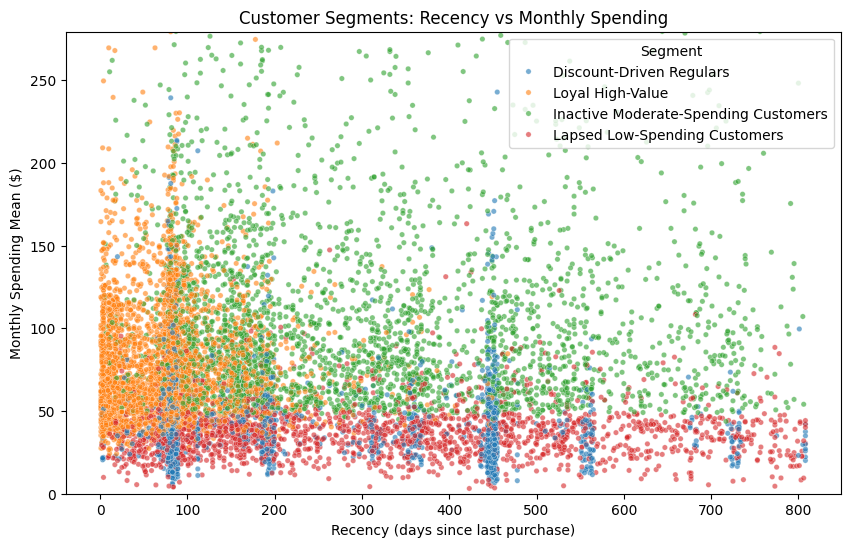

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sample 10,000 customers so the chart stays readable
plot_df = customer_df.sample(10000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df, x='Recency', y='Monthly_Spending_Mean',
                hue='Segment', palette='tab10', s=15, alpha=0.6)

plt.title('Customer Segments: Recency vs Monthly Spending')
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Monthly Spending Mean ($)')
plt.ylim(0, plot_df['Monthly_Spending_Mean'].quantile(0.99))   # hide extreme outliers
plt.legend(title='Segment')
plt.show()

In [60]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.decomposition import PCA

# Same 5 features the model was trained on
final_feats = ['Recency','Sale_Frequency','Monthly_Spending_Mean',
               'average_discount_rate','Average_Unit_Price']
X_final = X_scaled[:, idx_of(final_feats)]

# Sample customers: plotly can't handle 1.28M 3D points smoothly
idx = np.random.default_rng(42).choice(len(X_final), size=15000, replace=False)

# Reduce 5 features to 3 principal components
pca = PCA(n_components=3, random_state=42)
coords = pca.fit_transform(X_final[idx])
var = pca.explained_variance_ratio_ * 100

customer_data_pca = pd.DataFrame(coords, columns=['PC1', 'PC2', 'PC3'])
customer_data_pca['cluster'] = customer_df['Cluster'].values[idx]

# Colors (one per cluster)
colors = ['#e8000b', '#1ac938', '#023eff', '#ff7c00']

fig = go.Figure()

# One trace per cluster
for c in sorted(customer_data_pca['cluster'].unique()):
    sub = customer_data_pca[customer_data_pca['cluster'] == c]
    label = segment_names.get(c, f'Cluster {c}')     # uses your segment names
    fig.add_trace(go.Scatter3d(
        x=sub['PC1'], y=sub['PC2'], z=sub['PC3'],
        mode='markers',
        marker=dict(color=colors[c % len(colors)], size=3, opacity=0.4),
        name=f'Cluster {c}: {label}'
    ))

fig.update_layout(
    title=dict(text='3D Visualization of Customer Clusters in PCA Space', x=0.5),
    scene=dict(
        xaxis=dict(backgroundcolor="#fcf0dc", gridcolor='white', title=f'PC1 ({var[0]:.1f}%)'),
        yaxis=dict(backgroundcolor="#fcf0dc", gridcolor='white', title=f'PC2 ({var[1]:.1f}%)'),
        zaxis=dict(backgroundcolor="#fcf0dc", gridcolor='white', title=f'PC3 ({var[2]:.1f}%)'),
    ),
    legend=dict(itemsizing='constant'),
    width=900,
    height=800
)

fig.show()
print(f"Variance shown in this chart: {var.sum():.1f}%")

Variance shown in this chart: 83.8%
